# BRD4 ligand parameterisation: CGenFF 5.0 quality audit
**27 November 2026 | NP01, NP02, NP09 and WSH**

Source: the four original CGenFF ZIP archives supplied by the researcher. The notebook embeds those archives for reproducibility and parses their original MOL2, returned MOL2, stream and error files. Figures follow the approved [Figentra style](https://github.com/peterDataScientia/figentra/blob/main/src/figentra/style.py). No quantum-mechanical validation or MD has been performed here. Penalty scores express uncertainty in analogy-based assignment, not measured force-field error. The thresholds of 10 and 50 are reported in each stream header.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr, kendalltau
from IPython.display import display, Image
from io import BytesIO

OUT = Path('figures'); OUT.mkdir(exist_ok=True)
TABLES = Path('tables'); TABLES.mkdir(exist_ok=True)
# Approved Figentra v0.1.2 settings; self-contained implementation.
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.labelsize':15,'axes.labelweight':'bold','axes.linewidth':2.0,'xtick.labelsize':12,'ytick.labelsize':12,'legend.fontsize':11,'legend.frameon':False,'lines.linewidth':2,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','svg.fonttype':'none','pdf.fonttype':42,'axes.grid':False,'figure.figsize':(130/25.4,100/25.4)})
B='#0866DD'; D='#F04C28'; G='#080F1D'; T='#14866D'; P='#8C49B8'
def mm(w=130,h=100): return (w/25.4,h/25.4)
def style_axes(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
    for side in ('left','bottom'):
        ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(2)
    ax.tick_params(axis='both',which='major',width=2,length=6,direction='out',labelsize=12)
    ax.minorticks_off(); ax.grid(False,which='both'); ax.set_facecolor('white'); ax.set_title('')
    for label in (ax.xaxis.label,ax.yaxis.label):
        label.set_fontsize(15); label.set_fontweight('bold')
    ax.xaxis.labelpad=7; ax.yaxis.labelpad=7
    for label in ax.get_xticklabels()+ax.get_yticklabels():
        label.set_fontsize(12); label.set_fontweight('bold')
    leg=ax.get_legend()
    if leg is not None:
        leg.set_frame_on(False)
        for label in leg.get_texts(): label.set_fontsize(11); label.set_fontweight('bold')
    return ax
def finish(fig,name):
    for ax in fig.axes: style_axes(ax)
    fig.tight_layout(pad=1.0,w_pad=1.5,h_pad=1.5)
    for ext in ('svg','pdf','png'): fig.savefig(OUT/(name+'.'+ext),dpi=600,facecolor='white')
    from IPython.display import SVG
    display(SVG(filename=str(OUT/(name+'.svg'))))
    plt.close(fig)
def panel(ax,letter): ax.text(-.12,1.04,letter,transform=ax.transAxes,fontsize=15,fontweight='bold',va='bottom')

import re, hashlib, zipfile, base64, itertools
from collections import Counter, defaultdict
from io import BytesIO
pd.set_option('display.max_colwidth', 120)
ids=['NP01','NP02','NP09','WSH']
expected=dict(zip(ids,[1,0,0,0]))
def save_table(df,name,show=True):
    df.to_csv(TABLES/(name+'.csv'),index=False)
    if show: display(df)


## 1. Source archives and parsing
Embedded original ZIP archives are always used, so the notebook does not require external input files. SHA-256 hashes identify the exact inputs.

In [2]:
EMBEDDED = {'NP01': 'UEsDBBQAAAAIAJEre10BNEpJFwcAANMUAAAJABwATlAwMS5tb2wyVVQJAAMCFQlrAhUJa3V4CwABBOgDAAAE6AMAAHVXzW4euw3d6ynmBTKQSEqUgOLipm5wHcCxLxJn0VURFEW76KLI+y96SE4y/L5xEgyj0Efi76Hk3//y+vnjny9ffvv08vTh4evTh/L8Z21l07Zp36r9LV8+vX96Kn+8//L64eMfHz6X8vuPTe9fXz6Vtj207V2TfVKt27u+z6HYtlfGPw87b237+vwECFRDZqHtgRzPvQE/dq1St7aTbb/Dy6yFtwcGnve6FvC691Ht/NX4Bg94JSmyPQjgtNPsfvxa9m/daYzL+TSp9O25YwMc0NhQ67TzqeO/z7uc55O0Vsb2MACvu8JhC7cq+fm6rv6TUtHtQbd3a5/CkR5PU9vV/Lv1vzGXuT3M7d3cVdW9GbQcXlcz+Lfv+XyuVNb2sCwtg6unp1b1DbPJdUOjXuycyPyo5Fu0T99CNG631L2NNktr2ws+OC/TDp9Qs+9YcGF7uQlaVpPSUGV872Tv3NxGmxYHyrLmfdjIXGkoMz5rB5phgpqVoVma730ibBD4JJ5QKxQ2TO7eF7W97VKHhW4WyDoTFbFzNnjE9U2PUGl8cH3OEWkabmDyG5WoisSi1PjgymKJWvCq0Tj3MWADlYZi47NuakOiJLMaGWrXS3P3URqKjc/bT9RNTOsLq/a8dF9tWix5VmQjBMUOrcPCbusNPhD4CUJT8x0qIzJr1AEBp1x2tIodRmlyjg6KWrBVW5Bat0G5x9FPhGJTkNpZD6fEwuh7U73ZEGFIIdCaxGkKoGcK9PEdwtcdyoVQbgpidw7meWeA363fOdWGtkJje6GgNjkf+s42ydBgaAd0FN12FEyg3uTc1hmjzwmEnhd5q6MI5abpmZUZFsTYAHJUvXMJeemFFlxaUTy2Kso+rOy6r073LhGqUywXzkzGPIpxRhY1TGh9I09SGOXmGODtB1Uts9g46bKDuRdGudnKDfePmeOzeOxsE/q+QVA9thnOvmMpR4NUr3elS583WoVle2Zxp1ZdvmFJ947qYlP5f//NRlgGF+7bI3c3wpj1lqw1kG4Uq3b8LJkA4wsPwIdnCsnsVoyuOu24riJXvAKvfnwHdSyz0vv6NX4CPyOvzTai8Wh0EK92vnNnaOEF+PLj2xjNKYHOB7MFzXmBIwmPEnUWdKklCM4s/Bgzfd3AufciOEGak0HRQT43MHH82pr11puJqSEEPHnjrRF3hSyjeLUC8hUPlbCfP+v0ZEpdPaaxZjjhsi+WLgk2967sfV2dezuoen/8LAIPpcecxCvA8FznjK5XuuJRWwkqi1oc5r6KXT+s8y49A+mBi+JEZrGS2qU+HS6keoWjtPjsKcI64gnTHY6nz7yBjw5vYFDc6Toprjj2IY4c8e3pmLMFbf5ozAWDxXKKm30s9dNtWFzgKG33uxkZjFBbk1/DkS181u1ret+M1ge6coG8VzRq0d0HmrP5VYCxAjTmu1zRUFkeBjp+xS1Fgrb7FRxVxWfjQ+OeqXbBooXmHV8djZri82Ebs3MJWsbeUe0WvaqUjrx2dRdGD37oxKxueIfU24bBsCgdVevHRazTL/211G5J7TyvcGSqx1zmqh4xTieDz7sGYHsyogwjyMpsc3Ch7cnyIn20u9NnMdUIsno/WVsOPL947yT1Ckc4VnjAMZc4BvhqmJXoVbrLIxUgHg2FhJD1DaZkQzPj0hp8j64FM+LR5gSer8MIh9LiNQR0batd0SjECJ6yqh8uA2X4FRwltUGNEdnrcN4tHtOut9GvzYgyPo6YwNSHP5KnTVQ88eHcNS9QGarB5zH9iQx0A3yuuxHmcBg0HwDHy9kTtNYif2Hc8UiGFDTHo7+zcetR6zGv8eIVu9LXFY7oLSE23u02soRWVA0kJ7lJexOMjJ+/YX19/vj693/Y71kQr5/xy0or//zPt+///hcWP1F/fXn+W9nsT0uSfFnO9SE56TlJSXpJsid9T3Ik/UhSk16TnEk/k1z4vn0vP9eHxLXzU+/rH7Kd5xzrkCneYx14TudwkineYx0yxXusAz/SOSNJTXpNMsV7rEOupF+npHrqY33IFG+sD5nijfUh3VsqaR0yxRvrQ/aE70mm+sb6kKm+sT7wKd5YH3Kl89ep5xRvrA/ZTnysD5nijfUhUz/H+pAp3lhHPnP/c08/zedH7NGfqR9Yk4f5nIj97POjHzj6uZ22Ai816VOeJfGXU54l8ZdTnoWTPvWVyBmppDxLMFdOW4d+JH3Kg+iZAUnxSmRmnLYO/Ur6FG+PePW0dehb0qd4e8S7TluHPnyg09ahl1PfU7y9J32Kt4cP/bR16DXpU7x9Jn2Kt4cPI9ly/QgfZrIV+vBhJVuhp6RP8Y5gbk22Qh8d25Kt0PekT/GOYK4kW6EP/upp69DPpE/xjpX0KV5N/B0pXk3MHSleTfwdKV5N/B0pXpVTryleTfzVI97/A1BLAwQUAAAACACxK3tdqxEaYCcHAABYFAAAEAAcAE5QMDEuY2dlbmZmLm1vbDJVVAkAAz4VCWs+FQlrdXgLAAEE6AMAAAToAwAAhVjbjtxEEH22v2IknrG6quvSLSFEGAKLtNlFCXlGPICEFC5C8P+cancZmPEqitXTcXx8qqtOXZwvPvv+7bffPb/7/M3z4+vr+8fX69N3hS6r08X1UuLP+u7Nq8fH9f27129/uD68evvN63frJ9dvfvrt668vv//91x9//3X59fcPfPn5lw8/rV/k+159//xmpeVKl8vlU5KtcSmX2OvWzMf2UrZSvSzXrS60vH96pPFA2di1rLxceWKr0o61zYvsWNoYb7zHUqtlrcu1DmzdSu871je1kryd6gkW7y6rLFcZWN64afL2PrewzuwWizeSSll1edKBpXGGiS2lJS+rluVpk//zGrWy2nK1gS2b42jTV8U5eb3fnTd4jcvqy9XHU31rUg8/p8tpc5zk5LxkZW3LtY2/t83d02bjntjSKbA//nnrLDi6L9c+vWu1pKNL8QQ3kjMwwbQ1XnsE1gon3LUlnNnu4OHGAoEQLc9E86zSJmWDR2rCe0GYn2+PXR3uJuiLeNyRTSslObV5cIS/tzOndQSaoDCqqUluBzdThpoQxFPTAy4wXTJMqglvVQ+FFnrRdAW5TnKu8+B9SGGgYXo9y43ddAiNbJ62NTu8bgd3q+cRD4kTtEY+7e1VjpjXfohcTuGsEAxBbtSmzsnkCH8rmddF72oCXio9Tg69Uc8sEU/y1inRjc6CxpFhEY/hoZHbfKC9WPqN+l1ujzxBjjGKGdNEu9gRM5to1JomZxUpIs5RzvZ6VpFcR8TrlNtFELPBzTf5HWnGkBtnRWM+Ek3y3LqR+wm6RKIwShrvNQ0pQSV9jppwoKXeomG5kgMNtXFWNa1HdQmBDjQKHOkJN/dA2/LMWdc4E1u3mj0A+kdhg9JvuKuG5RAbZ2XzdnSQKAvTaypnPi9GQENr3GbEpB3cIaWBRraXM68JBLFyh+U91VJndZLNpuyA7sonlgvK/RrurGVGzPvRCzi9Bm4vJz5nVJC1Qms1Oyf9pzhlxPCixmdqoUBDa3XXGg77b1mOpjfRFV3xPsdgG9DRPOtEd6+HUsuhtcJnXbtAT2uV5anKtLyXnugueugcZQQ98I8PN3iLiFddHqpO9opWO73ebURyj47ioRvLe1huwNr0OWKjM97q3lLRLnKOdWB98irKwIyXqPaPYhuwLaNF1Se2sA0TUFeK1hds7sD2yUtmNGOFSWR/jjYxp1Ms3PggqTFBRk1fw+Q+n0NX7edYvFJ2hWE6gKYnb0NNnudFvp3bLAwsz8zodrRw6cwTC93UcyxuS528DZLJnCxd53MoLH6LrWiMa7hfso6pes2MLLyHi/BceYEXR5FdV1GRdwcBW0tLbXBzPsdCV5I1TFz4OK/vvuLoyy/4GUeRrGBVpphirmuJFfa78+5Y6EraDIxWT006GvHEYpRut1iKqU5gjuQhS+NjVqnUp6+k1HNeFPOHWbBQu0TqNMGse/LGaHSKha40hzLE5fAVkXwUC/crT6z2lno2Upt51FG4zrEIu6ah3BpNLJpL5iBa7Xn+Km5Pjxq813PAYBH6KBa6Up283Y+poOQ0BZW3+3o1YqTQ1X6y0d2O/tRl1/Ml5nY6z0FF6NSnoaZH7nvb+yWwGHnO9ayQjB4zmLccBnv3nINc652udizcr9kVa/F0G3g5se1ekwOL8ebBsl7VWus8uiqnn0XtvNbFbct6Faqf2Gr7JwCmL2U515XBDcYTi9KeMiHt+3MoA6Z3vmIM0atBVxMA5/KUNvoR7ZkZE4jVcz8bJDOrKb7LbBYaSKztLge2UH/hvAi7Zb2q7skrpv5RLHRle72CdcWy5vRqu80Itel9HmEOWw26suyDrJafhi17GT6FcZRzXty2XVc4pLX8MgSUJrb1F/qCwRzrE4uPxnR5733XVcyoL9QNDCMPXia2MmU6Stk/8OArjHzndSNaq9M8L5WZyghX2UsXdOUsd/Gt+OT79/86vnx++molPIFpbGWsmGzWihXf+atgVfwqVsOvYXX8OtaG34a1L4xP6b7gu4niszguii2N33htLLhb8SSWuOLlseCK98eCu0ERCy6PZz1+KYhiwdVj2+OXgw1LXMGGJa5xCI5fDrZYcAUblrg07ur4DTYsccWZsMTdYMMSV5wslrbUYMMSF1hixo0r2LDENbxW47cGGxZYNm5q3BmGYcbDIeK8aF7xnvHvLQ4ZrBin8M74Z9QC7MI+icjUME9GbOI5jCHYhSswVCBOYRtGBMQqHIGGj13QoX3jbnCgGePuCGiP3QhpQQwlOND2sAsO1JG+SHCgJSFoEiToMNhqsKAXxDZoUP8RNA0elPPYBhGqc2yDCTmKOAYiamecewiIIniBiMoW22BDoYK3AhF1B3EMRJSR2AYbqgKCF4hIckTKgg05G9tgQwrGNth8hMmCzUeMbCh2hMmCzUeYLNhcYuvB5iNOHmz/AFBLAwQUAAAACACxK3td4OSJ8V0DAADeHgAACAAcAE5QMDEuZXJyVVQJAAM+FQlrPhUJa3V4CwABBOgDAAAE6AMAAO1XbW/aMBD+nl9x66dW6lDeSjf2iUGBTryJbj/AJFdiKbGRHUr59zsHSChlWsvaLkiJII4vvrvH5/PjXKvXnAwG0EWBisXQkSpA6HCMQzhvkbTTuYC5kjPFEnhApbkU4NdsS2GMTGMIPxYCwbVd32rJ+UrxWZSS5oUR2XDH4+A7l9DvtywmQvgleGYkXYG8hwFTq5jEl3AXRFLGRjaOmEpYsKpBM45hYsxpmKBG9YBhzbL6PEBh/KayYbGAhZjwABb0Pu+JRe4lHw/4OOcKdQN+RgtoYwCeA7bdyH4Ga92iKbFwrhJYMiW4mDXgdjCejMY3E5gzmj6mqEDIFLiAgAkpeEABu5cEN7VaXXdS92FoGhdMr2Wb3p0H5vLtGrkBO+tkz5+aMKX4XQILk41rpgrX7dveTXvS7BeudeZbS5Vi+Hz8c6gHx4c4XdBo0wXHs69gKkWoL6F+fV0HJmYxUsf9avs+hDzCkFKCBP6Xa+AJZcGczFrw9DLL6tie73keBLR4LMicL8lxZBY0kEmCItU1ayiXJpUC1JowQyJjDBYxwnBsO1Cr1SxFYnKxRalTqWih658TTKZoHs0AE36dshkl3X/RYGFIo5igjFVm9Svd99Gt1nKri1oKGotb7Xu5oD03xdQQUvGWNh+pLXkaWWYfkrIN5/SfS2JCIsRsp9ogcMayLvGi2akX6x1Mw1IScKI0piRRGrGqgaL/5P/9HRsqEyyWs1XumYvQhGcrNqHb8hSRrkecTnc3uzvrZ//1ZojCnaLxHEPr3tg5As8TJJnNtjM6wo7zFnZ63eabwsktZE3rmPjsGxoa0bFx3oGybtwDls50wlQKLJ5JRQmbnG2yWUig1Asi46U4Qr9ZmtJ6LU0lnOFjxBZ6ndO5hdfiHW7mfSp4DyHNGvdQ7pQE8AbiCQHeQ2qa0VU58Y66nu08wVn6BN4N74aW3UNMUwq4BuAeS5QY7f45+Y/HbmGn1x0fyqgXHgb7DFCq8BWzdV8XrzzCFKW1kZd7zDNpffS+UHFb+O2dA8Pi9C5VZHfhEi+NCK331zPgI74rd/ZGkaWH168E25o+Ft2Xgf0IM88tlDp4Jwf3zSqeqnSqSqd3/zQ6HbynVuqdGt6qNK1K06o0rUrTDy9NqxL3NErc31BLAwQUAAAACACxK3tdX7+b/psUAAD4bgAACAAcAE5QMDEuc3RyVVQJAAM+FQlrPhUJa3V4CwABBOgDAAAE6AMAAN09aVMbyZLf9SvK78PGzIRouo6+1rEvFoQMPIOkwczb8PsyIUNjekYHIckH8+u37q6ru6UG724sYWyorjwrszIrK1v+Bdyun57mG7Ddbcr5EjxUixJ8LlflZr4r78Gn58EvYHRxcnN9Dc756AK8W2/uSvCuKhf34KcRHX337mfwtFl/3lD4r+VmW61XgEQxhaRTwZdtCb5Vu0cgpoLd+mm9WH9+BvPVPaCU58tyV2444a0GTxj4YEBZugeb3QO4m2/uwfzpqVzdU7S3AkVFAf6vsIpTAAeDN+BvlMX5Yvf8N1Btwe6xBI/V58dyuwNyHGzv1psSrB/4w/l2u76rOPsa/TaiaGZ8NhNwsf5GSe4e5ysAY1Ct7qs7Ol9A0zmMO0rpYV5t3koaDOpTuftWlgyEImPcJzFYlhTHdr0swaf5troDX+eL6n6+YzJQDJvybr1cUv2W9yYizr6gTzElBgdPa6oxxQIjsaR/sQfl91252lZfS4PC8fppVy2rv/gv0WBwM/5wCSazGIL6C0ZxHIM3QhNKX/8BACr4g7fg7nG++VwaTyCOsoQM3txcTs7BLyAFIwxGBEwSMII5/S7ACMXGY/aATsrAiD3N2CwTmA5SCKrlEaR4YMrmmM8Rot/0CYb0m/6MMZhgizx7igj9poQQRYdjNntwfjP9bWZISoVkhno+pj+OLn6fjScnV7cfwb/or+Mr+tfklP4Zg5vJOQS3H2fsB6R+wOyHwcnt9Jqyx5GNzjHlCBzFEcoSipp+xRFOCvpvyh6zAcL/SDCkwJAAgzlWYChPGsGwAoMCLCaxAiuK2AfjvwOs4YkmSzgQTIiAR1GS5Z3wk4TDUw3MBP2UrjGHJ1EWM5ky9jgAL36oBUldRlKkEMVFQH4XPnP0F1NT4fA4Ihh1w+cSHt2kUCgSK/gswyY8tuHFD1AjKhxEEMVKo5g0IqrhYWzAs9WPtf0wj+uCn0JugNNzHAtF4Cy34ZmkU84Q/6PIItts44I0kLXsD2KX2yawBm5JP26TftymziInNRju5pZtTxY8SrAy0gSlBxgJzCX/UFg7KfLa2gObRKPbwEIikmaPlP/BiCSNblP7P4oVI8ptkLLWGHX7/whBmz5U659R+NSHV2DS2tAZnHJvV96GKNsENCtSwSuzOxtBsejCSUTw6VyI2pD4biMQIcZ/QpeYI2LeipoQGfCJgkdcEFRkWv5m+9fwU64j0/4T6e1phAs2P2z/SBqitn9qj3vYP5Jmh6aJMLs4VdymabIHt4XgFp1hTpbETd4KTW6x2tKkkhGCmmzc6DYGPDTgmbVAAQ9hVHCX3He1sdrkuNkya4/VJo/yRrczoi22rT3OE2W2GeyGp4kJ+32ivS2tVzvNGW4dLXHI2y8wt7aL8xMslV7Etv6ZWBdS/7AGS/uBZf3AcgmGDgMreoGRWILBw8BgP2qoHxgWYDMJhnFtN3xxGsBIM7UsaQZL+oGlzWBtsmX9wKSV8LyB+3S6F5iyksNsMon7gcF+YKgfGO4HRvqBJb0WIFFWcpi/Jf2sJOm3lyRFI5MwaQZL417U0n57SaqshIi5COG9wPpZSdrPStJ+ESdVViJli7NiL7B+VpL2s5K0X8TJ+llJJq1kdnLNU1aM8nYwYH+94cWGy8nN4HQ6ORN1Bl41eMMhYznMRnhVwB5mI/ywL4ahHGYj/AxvDfMRfiK3Z/PsJvOG2Qg/P9vDbISfht+wDEwPsxF+yLVnsxF+drX45iP8bGqLw2bzs6eNm43wI6WDhABxZHSQYCCOhA4nKRAnPQd3BsS5zZmdA3EKc4YLIA5X9jAb4WcmZ9GYlMiTko3wo47NCRvhBxcHN5MSJd5sOsKPGbZO2Ag/RjgkEyCOCQ7uHIjsX+COjWGe3duz2QhP2m1O2AhPwZ3ZTEqMvWE6whPmgAaxa2x8oqFBc3V8+xacII8kX2LfkLljYt98+LCrWDnsK5YP5+Hhwh1mAvLU1h4mfNgzHzHsmg+Xm6ee9uyUD7tOIoc9KTM+7Ekphj0pCz7sSckcmKdugeHEk1IMe1IyB+apVWjYk1IMe1Iy5+apjzOcA5HaOMMFEKlLaNhfyxiI1MN3bp5ahIb9rYAAkRo4wxkQoT807Ekphj0pmV/y0OwMM32nnpRi2JOS+SUPnYHhzJWS+yUPfWr48np2o+s/sowjikjidKwmiEqFLK+IAoIoPwwG48mZvIUStxL8HuphUX6vL6Nm+uLGuozSVyP/y1do///vktjqfxjIAp+q0xHCch2ezcAIE36xNPsYoyFAj0dPzxvKgoYQJRpMSA2RxAUrTs7nQ/CwWS9V1Y1XwYb1DVSqkMg6CyDIJJskjOzkcnTxFrwvV6v1v1PV0PVhFrJbg9X8/vH46akagj/+eILH8/sl+GMTgey4SAaaoChE7SmOgOAVN4STCCkIIu5Kbme/Drlp3v0+nysAWRAEOE8MEikncT0d3w7Bdbl7XH9/pn9T8x2C79+/PQ+knhV/ODb4IwkHvhnfXk6mVwDis9MhOP2ym99XFAH4T/al9EFnZ+Do6O8cTDwaSKRtsivcp7djpoOjT1+onZQGJNeBzVXOIU/H0wlVApu/ZtL8WX5d13DSFNLENAVkUrwejy7UfHXooNqKEjUfxh0cMtZkXRNkJocIc8iT0XRIl6jcUf4AMwoIj+N8IK8C1P0Hjs3lyrilzW6mt9RdV3/xdfrH+APIj1FynBc1sLgFoJQMxRScrGnraq5p69BAwrUUQsI5eHosh7vnTZADZW0WMM65ikfT69nZB0pxuVDTVc0AmzYQ5x4thxR3RvkPQAjVq5PENex88eecqvjLE9tqhkD63xDgY3RcIAMN8tHgvAca4qPh3Ly7OvnndAZmlzM4REOsQFRRAcdFLTyE8BDK5HUEIPriFaCAUxm2w6TkUw3TIQrHK0iEmpfkkJVFhy+JBME+ZXSILhkaFS5Qig1dZvxC/eT6cjKmeKqnRxrh7sB8Wa3KrYJUtYCXaLBjMUOik5oyyom32QVAmJp0aElNKpDvVTQW7B6fFyyo0J1iTlMqBaUqQJjquI+IE+U9ovxBSBbleuuARYuOpVZU8ZzExurEpDavVfmN90vt7h55tkK3XJroLLlA8+Vyvaq+LMFP79+DGB/DmPL082BwMjm/Gn8w46aRewCqIFE1gxhHSS5digWEd+8dGGU7QCsVCkX1zjSkZdvYkyQSN98Q5hFEBkfovRmhjZTD4CjOI37f52ccNZiyDpCkWhBuWizvOP1tCOCRzDyO4BCzACoSiDoDYVRdZKSIxB0UhBQtMfgeJU6SqBIMQHLNQBw15VYqIzHh0khUH9kKFEze0U1+VgsMnC8nq1O56n70aziVdtBs07WAEN/QoufIiyM3V5sN2YkhnKzR6QlN1jiYmawZJKRB1ySgJGHl0qYy7ZQ6jgoHZ0BcmHts0xSTWYlOM50sMmCjStc1U9D4Z0qoHkRjFmMqYabMvmfg9uZXYzlNEp7sTF9NyWOLdIUtXTiFdOExMqiS1lS39tnaJKiIhXDdLMqw67otlmymszSf1UzAKA9ol87mkw3lYlO5nmY70NsyvhXkZhfX74csNVw9L+S2TIXf8QlKCUYurVJqQBzboEqVSTaiYStFOgAEU2srwwYkkVFH25mfYOt0mlgOkPo4pWF5OMenYyo+l1Dn/cv1ffVQiSIEkxY80MN1tXzarL+yaED3he1DuZl/qhbV7tkhpbZRGm1dNzm9nF2MJx+vwAldt+n5h6GVqDv5OsCeKlU0RzSuoCSkSnV0cRJ4LX6CIyxDEpTYc4UzSWGPxN5MzEGSa/TyOEfJ8DauGr2V6MozUsMKmjRU3kvPMTJ3YjSgVAu/jKVqyYpDREAhDdUi4CYRri5nl2fg8+L5rtysFwFMeyujOUf+YTITHz1KNXoo3MNH73NqOmutPqj8i26CSeOhWAA0HI3NoxJIVEmJJUScS5zpDQWL3Jl3QftUxCkKWUEodehoHRCsYwds2mwY4wzA4Vsvmcl3vRFCf/NShq85dA3fwPjqRiBZ9BSQaEWjCNs7N4wd3+VsSxSORqSOjdxcVRGM+ApRhAIrJwuESNuHu3IGVnWYMhiH0De5M7X5s/kGm9ipWGkL9pkMpx5dTDSnHkZAqjcLz2/CRq0Mp9Goba4KsZI11tnHm8szdnKj2W11z45sQ/BcrZxKjQ7B++yGhs1tfTx47121BY8WCLP+8P19YOsUcF6Ex7ASfcSju0Zme/l7NFoNwd3ncvXw8PvdmuUMy2pbp44mGs2OsQG/0v5+MPqG+oOnOBKlr7QJBdcXRUQabCF4TmK9Ccndfja+BE/rxfOy3GylWiW8hy1RcutSTyLwM29DfcqYxhYPY2+Lb6hCOuWfnvHW3DAO4wG9Eg915LBQ7RM5XFTGipFDVyxcUFQ1r1czUZnIu+iptIVOSHLWKHU9np7qKx59hrib3z3OBxLM47GWM5cW39MyzZJTHcOyKNfbWwGNCs7Z1IFRNT6AC33cwN21sI5SmIc8cbOremvUt6PUsWOwXvHLVHZx88gKg+x7enr7L3BC/9ZPWcmTPxcbAPg3VdAykzAdXI3gnIiQHqq2Nx5CaoyqrGmczaiChfforDTOSGNFn2MIpHt7Me34EB2hepv/SdeETaH2xC8BxWx5cHWQH8R/IOM3yoR1aNeJcyyLLq1XnsYRWaNI6w1EVqXaXGpwdnkxPrs5ufrgFF7d2iJr1kvY9gOg/C1wWmAshOCtBKvYgxILT/zthRdS0r7cSCnNFSWYByhNuHY7KaXhQrpO1rkp5B3a8xE0Je5thGJxCdKmvBcQ0sFFNm/G4mUNrTvjmsDVvc9onLYyOpGH246TzB50csXnq9Np0Iem415SuNcmOsqwYFWkni06ocaD10HBXvjalvuHnUZG2UscXe5J93kL3lUooieWfQgVnoW9GiFDdTTTgo2qF0tn3O241yX6Ok60ToYZZQj8bQRNzcJzJx0aXkjrdvUSOrpyz98Jgwg5dOy7Mx12GlXCWxtslexzj9aBGCbSzdCrILaE7onY4DFwk8FWjUDWYNmizSAKfc3AnQwX7Sg88RwuIHUm1tLYaDtTvQ3CqWFII9ObYBKmY7CKqbSNviTvPL1LV529cBsPGU5r41cLuoZV7YtOthjYW1IrOv9S2BK2KDxhbWV1wGe5txUfBI9IYwxvuqCW2Bq93E02ggisBApH+5AKLOSPIpX4kfyVSWmvDCjQvjV/S+P2UbWqdtV8Uf1FozdnoXVjelsbczvxgEr/54gHlPyDiRu5FvTVbncEQB/aagwgEekkQ93TV/ArkTEi1w9fR6/XxHCWeJ8tICCmE1mUs7SRQoacXUebF5JSKm3dAl5Iqj5X+wrcfvp9vQMoZrlsBz3USSGot1elEFTXa1AwzwKdZjYNOJN9GCg66bDX0jtT7FegQ7cGftojP4KOtTdkCTvtWPLYbWHhtqyR6lDiFpruaaHIX+Qp6SSQhTawFxMwtMDKeB6Bjm4tI38OLV9AJXrdiMck39TrNDoiusWok1RQOX1J6XPw/mraJ5DY97JvnbcYzOW2IgeKPdNsPBcF2q+YdZNm3Zyxj1+rraSj0+v25teBVEUjxyjCCfsYiRaOgyjsk5zPsdsZJ7rGbk6u2IsXm/WirKjel3fbcHdjYJdsD1tmsyPUb1ZotRC7+Be4oLcJNWQ2dkslv67xXlXyDN52MT9qKZ+9vfY6F/fURjcGu6aHGzHMbqZX4da9kergY+fPQFWus2nP7t1rwNLYwLd3H5/dzrcns2C3XnxhvbjsNsls9Quj153QDej36uMbOe187NPCQltVWwcfv8tvEBxFpLn2+s9pGN7gBoX2IefOKgDc1Kt0CJW9l0dVganmwNHfGTKjlhNeMHOz8soLHyZh+C6GwwseBdgLuoPl38jP1ZrbWts75YINcyJIdZ05PAStrXLBjrm6fJ/uLUygey5g3voOlN92JX60ZM31q+fFEFyV21X1J7UZMKe/0cQrDmN07jyQZLo+xDOLlFZo3bJn8pbdNzarwpb4V3KhK0x9j//8/UsnVrWM5ECsTjOqd0GR+FgnJ0Ow/fJ5vmkGJzZT3o1RsKXX39JJmIJtVEXi5QMWg6QVvItBYjHotAWSgcT1Av58xY9ENaSRP/eCyNUhhXYuQ4JEdOx96SrBKNTiHTZPuxjWq3fcddBOA3ipgj3xAwoOEXk1BTttvq16gM16IIeuT+gm0uIS+1fqATJdqxXo9rJ96tA14wjal6yBhrFkAUa5vU6OduVmWdGlAScn4Ahsd+yjEzbm50LcrReL6p4eHflnSNSL0ET0xU4SRHyQk/j7dyBF2M9+/deR/fczRk4n3+E0nJ047CKuGHsYXxDJyy24BydBJIdyEkwtR1bvCGlTu91JXjeOaMUn3ksS4SRqHyJNYRY6byGExGizHvP9g7AULIQFaextoT6NgIUaS9ogxo/ddRrk6tgcAgcHI8eD8gqorW6tj+t272RdkOmkoi7N26rWr0Elae+k6k9FN1M2+FwHFdEJahExQ1ZIFLjPftrYztpAwRLjMApOMytxDPNQEbgFt0sQJLC3BB4BT4BgXW5SuzNk/0FAU/PBf8Wd8Kohlbj8tcE7nt1eHrRb0vbcG9pfWrHfrghuo8hjSrwjWb8+Ezjfd+Uj+x3zg283NLhkK0ZfzH4h3kdyeIgPpJP63QGOJA1nlZv1TnyE2Kf5ZlPREFKtwJh9WlgJfvrw7mefvVfDHDR5K8WPdVBxLR/G153wKEIw6Nlt8FaraaCwfojdN4sU3AzOpmF4i6U48ZU9voyH/I2HIX/lwX/BwTNO+5DTvoPD9hhh5/Wh1xIaaDgm/Db0llYQcdfmvdd7UIdooCNK2seO19eAj/hQDdivTh2qgc4gK7PaIIkXKyCIuIcCjHeq7OZOCZZ6e2xzw2MTOnUlELP/OMJD1/aCCvtQzOlsfON+pKKXD5A0yvl1QGzibmjbMyr11t0nzCO3a1KmEfUdLinY/5WC2wl5bdju5XMsPs2T5hu/3UwG/w1QSwECHgMUAAAACACRK3tdATRKSRcHAADTFAAACQAYAAAAAAABAAAApIEAAAAATlAwMS5tb2wyVVQFAAMCFQlrdXgLAAEE6AMAAAToAwAAUEsBAh4DFAAAAAgAsSt7XasRGmAnBwAAWBQAABAAGAAAAAAAAQAAAKSBWgcAAE5QMDEuY2dlbmZmLm1vbDJVVAUAAz4VCWt1eAsAAQToAwAABOgDAABQSwECHgMUAAAACACxK3td4OSJ8V0DAADeHgAACAAYAAAAAAABAAAApIHLDgAATlAwMS5lcnJVVAUAAz4VCWt1eAsAAQToAwAABOgDAABQSwECHgMUAAAACACxK3tdX7+b/psUAAD4bgAACAAYAAAAAAABAAAApIFqEgAATlAwMS5zdHJVVAUAAz4VCWt1eAsAAQToAwAABOgDAABQSwUGAAAAAAQABABBAQAARycAAAAA', 'NP02': 'UEsDBBQAAAAIANkre11WzF8EtQQAAO8NAAAJABwATlAwMi5tb2wyVVQJAAOKFQlrihUJa3V4CwABBOgDAAAE6AMAAH1WWW4cOQz91ynqAl0QNy3AIIinx4gD2Okgdg6QK+T+H/MoVafornYcFCHTfOLySCqf/3n78fX75fXTy+X58fzz+TF9+545LVoX7Uv2f+n15eH5OX15eH17/Prl8UdKn6+gh7fLS6LlTMuprzW3vPAq2vNysrp2o7ycV1lo+fntmZa85tpz4uXCy4nySsR5obW04vZlrQW/X3b7U161kyVZzjIAvchwYOoAWztVd/Dr9+6BCgC6nBUAWObigMI8PVC/AcBFJivJlrMBIWt2C1mFeLrgqkeEVk1lOZfhwzwoWauJI3TN1m6DykyU6nKuw4UyrtRVyyiTu7RDFtItteXcAFBcXRwgbBug3fHQWurLuQNgqxmuNkQyAAwPcvDQS02g54LvRKh9ZffRet4gVZwLDmlzKz2Rk00jrMbFvXRpDiGU/ugld03EgPAITAvcwRkNAvH3psfUGyUSBCYjsObV8t7oE5L9itsmUU4E0slZryAPkIb0aULU6qEPUS4C6WSzwoQc6mrqqWhfRQ6UZC5IBaxTGSwK1wHpNCHKd3qxocYVqdTZKZQ9LtztkLYWudfvSAXMU5sN7F2FyWKakF7t3kgRqKc+EMW7CWXz0RjJ04EVRmWSu/YeJ0Iqg5WWbULMDzdxtWaJwT3TmMTqY2Foly17Mz3GBSegnnl2vcxuaVu3sBN6U69WW2JQzzJSqUIO4UKzJ6m3255UyzUxqGcdqTAVH0atPEelVjmOb8bAM8hnG7mMCsFb2wa43JkWbJDEBZEVX3TZ02Z40YnQ1u4QqYkx8/hObSUda8Vk82Fyp15YjW15wgcXZOgA8dzr2KXFXT4F81Jg3mHeR0QFkfkqdX6soZPR2bfm8P3k/pGz9VJ8MaJF/2JPsKdJhY4aMRga4ZD2G3vDnmbY8xgoMjHPl3xXYI0aLnxvzyWJwF7GYmAdvJVSZPDWONN7+y5JFPZzxA1LFKNUtJXZfyDoGD9CFBtbxDxepFmKje5DC/SjPUIUn+62MvY+pruz0V/sK+zrjN+7GzRXrz/mFGvhxr5zErArc665KS3gQVgmIPuOOjjAHdJHY6uoYhE0bbQlXOrBHj315C2JcWPqw0E2n4wPASiyzonGYDKWAI/H2zOQcqyoQqU8Jw0DPB6MVsf9pd8y7PZgGB8atDQzXxjsL8GH5iBYdS6YZuqvaq88Zr+R3jYoJ1fhO9UVA+jj0sS3M/rH8OQdr4dHfDBnRVnFH0Ed7ZmL3kkW9dIxvYay+wPcxzB+YP7n/0T/Xr79lxb/oSB5HNN+3qQEvQSp+H79Tn/OV2lBb0GWoC9B1nB/DbIF+xZkD/q+S2wfDznt501Pu/04XyUHPQcZ8t3OU2rQa7AP+Y7zVYZ8x/kqQ77becoW9C3Yh3yp75Lzbj/Pm6Sgp2Af8h3nq5Sgn8wOvxz4HeerDPmO81WW4LcEGfKd52m/RL8teK9Bv0f+jkeZ/NKOnfdL6OeJ3fS86yXUTfZO3rCbfu/kDbvpZ+Rtx276mbvu2E1fg96CvgV9qJvMmC1gh15nzC1gp56CPuSrvOs15Ksj5tkVGvJVDfqQr1rQh3x175ANu+knv3XHbvoW9CFf7UG/5fs/UEsDBBQAAAAIAOsre11vZ3kR5AQAAJoNAAAQABwATlAwMi5jZ2VuZmYubW9sMlVUCQADqRUJa6kVCWt1eAsAAQToAwAABOgDAACFVtuOFDcQfe7+ipHyTMt1tS1FEWSysJEWBu3Cc5QHIkUiIYrg/3PKlyYwvbDb8rjtPn3qcqrcT398c//r68vDTy8vdzfnt3c366vXiU+r5pPWU4r/9eHls7u79e3Dzf1v59tn9y9uHtYfzi/e/f38+enDp4//fPp4+uvDez798ef7d+vT+b5nby4vV1rOdMLfk7rlVFJMT7yJ1pg+sbxVo7ScN1loefvqrj+btlQ1rbxcOG4pbUTcsbR58Y71LTun5fI1VnJJqyxnGdjqsvOadqxtlXLw/v7v/8CntHHKadXlrA0MRPIJduZJTPUaDGZiSqstZ2tggRe5g2UT4snMWQ/BZGn15eyD2abZsmWTDtYtWTkCpwRwXs55MCtrB+umPmId9tiRz1okrWU5lwZW0PkEC9sOLofMUlJa63KuDWybWe1gg60DzGCWI2aDmSvyf6H2ICGlmSd3qWmHZ4lE85fUGommUBgNywv7JK9SOpo28mvysJyQLWLAediuTh0OO2goBYkp1/kKpUS+SGC7DNvLDHoos054cjoQKVPYDqFRV1qGOQNdEDiaaLV8UB6UkDGC0shmzmgUV95Mu+daN5HrhDepQeQErZEPvQjnHV5pwpWPa6QFLsPzPLVKadoOxg4vm8uj5UmQG5VZYzaUjh7BNNE122ONgaA3qgPt1WbUC+U9bnQoOEYNr2FVr0YieL7nvCSbcMP0IGlwbmUIjrvgEuSqU3Dlc9zM9LGkMfTGPKtUPsu17HJlaOfI9Brk0BvL8DwLTTg7zVqhWg5qJaMyVobeWIfjTD77i2aeVZ7zYa1QyJUhOLbheQS4wWFH2duTH9c51Qq4w3ZvL6zII024Zp1wLeUxxTC6G+e2UjbSvbGa7OQmR2HvR0lZbrkMbrImvUAjbk3DOIgcFi23X9qd0IJWrsDWabd3F9pB1GVgBSWHYjzCIhq33T6EzKr78NnJy3exBCzNXOsebi65DJtJ6xWWkNdVGNguM4W/YjNa1HsljiFL7sdYAbZrDMLSXSXuLkMlhRN9jeUcWAV2djTTJrboCq7FZ3HgHD32F65Il5cDW21gzd1GaSTzeoyFK9KbWUGR586Lrws2+i42A5unv7MkIbLc84tehJ54he2xgq5k9jEu2jaRamGZ2BQd/JAXr5Q6qlFFu811K1poj5XnQyyEfturBm2EqU7eZL2+v4lF6nQ2MPQdbpuOVNfZe038OEeKZeVhM6NTtc04q0sevF6vddWx0JXKqCMv1vOLxsn9AP4mFrpSHTbnYjo0mWtuWPS9QnpcC7GsjexJ3tBgZu0X6ccf9Gz4PjnmhTnqA8sqdWCpuo46Sq6PxArh19mxDFkdsZI6es43sPtH9M+XV7/gI5oW9HN8EPOC7oaPW1l0YXyn6mK4N4yOe8eYcZ8xFtwXjBX3NcaEBQyY4XXx2RQXxyLHL8WLY8ClMdW2Gq+PAVcwYIgrSGLAVWJa2mpQxVAXnLAUx2xcwRYDVoMtBlzBhgHvDDIMcVnsW/v1WPX45SDDgNUGKgFua+2NzRu0WUQoTJEWq7BE4gSMjWhoukh7LuIVG9FsyiItmB4OS5iBThDT8BmFHdMwA3UK92Mvyg6+xl5UUUyDCTnENPZC4/A19kKyMQ0yKDCmwabNYw026ANuabBpadNg09qmwfYfUEsDBBQAAAAIAOsre12CcEOrxwIAADARAAAIABwATlAwMi5lcnJVVAkAA6kVCWupFQlrdXgLAAEE6AMAAAToAwAA7VXbbtpAEH33V0zzlEiptdiuaekTJYGkggQ57Qcs68Feyd5Fu3YIf99Zc8uFPARRFVVYgD3juZydM8P0brrJaAQDVGh4AX1tBEJfYpHCeY+0/f4FzIzODC/hEY2VWkHkM89ggdxiCj9rhRCwIPJ6erYwMssr8rxwKgYPshA/pIbhsOdxlcJvJZsg1QL0FEbcLApSX8KDyLUunG6cc1NysfChWxSQuHAWErRoHjH1PW8oBSqXt9IdjwueYikF1PR+I6l6k2VjD/g0kwZtB37lNVyhgLAFjHWaj8Mae3Qkns5MCXNulFRZB25H4+R+fJ3AjNPxsUIDSlcgFQiutJKCCjbVBLfyeoMgiSO4c7cAnNRjTnoIwV0R8ykNsEZonj91YUL1uwSelqvU3GxTX93eXF8l3eE2tW1yW20qTN/av4W60z7FSU3WToRWyL7ARKvUXkLcbsfAVVYgCcE3FkWQyhxTaglSRF/bIEvqghmF9eDl5WhtsTAKwxAEkcdFk3xOiXNHqNBliaqyvnen566VBFpLmKHUBYq6QLgbswB83/cMqSnFGqWttCGi488llhN0j87Ald9WPENofdgjOIAHT1Oy4oo61jj2/54vWq3IFtfeU11TrSdYuUbcvqWik9tcVrnn6k/ODM7pO9M0ATQIDUMMFGa8EWkeHEMXS+bIrCKFpFbmRlMr0zQ5KPa9/P8sMdVxiqI6FAD2PgA3Q4oXOltsEEiVOn7WasfdekDgfhAmMWuGPm4vb8u/gDjcEerMltxUwItMG0Jenq2OpzQQBpG7NNsh/u5ZOt9SW2k4w6ec13Z5uE2EgwC+GdDvceLdVdmVtFeo8EWolqsHa+1RRNZaR3h++zCmt5GCFUVHTMcrpCuO9goVHC5U+xUhezG7C837oI6FkJ2Aj2ugjx7gCtlznPtM82kbnLbBaRuctsFpG/x/2+APUEsDBBQAAAAIAOsre12M/nq7JgoAALQxAAAIABwATlAwMi5zdHJVVAkAA6kVCWupFQlrdXgLAAEE6AMAAAToAwAA3Vlbc9pIFn7Xrziep0mKYHW3rpOarXIwwd6xgcVOTXlfphSQjTKAWMBxnF+/fdGlu9WSQJPa3dqUY8NRf+d++pxuvYX7dLuNdrA/7OJoDY/JKoaneBPvokO8gM+v1lsYXF3Mbm9hxKkr+Jju5jF8TOLVAn4eUOrHj29gu0ufdhT/Nd7tk3QDTt+mSLoUnvcxvCSHJYilcEi36Sp9eoVoswAqOVrHh3jHBe8LuMvglkVVWsDu8AjzaLeAaLuNNwvK9l6wSCjgf0VV4gGyrDP4iaoYrQ6vP0Gyh8MyhmXytIz3B8josJ+nuxjSR/4w2u/TecLVL9jv+5TNlK9mBq7SFyrysIw2gGxINotkTtcLNF3DtKOSHqNk9z6TwVCf48NLHDMIZca0d21Yx5THPl3H8DnaJ3P4Gq2SRXRgNlAOu3iertfUv/FCZsTVF/IpJ1fSYJtSj+UqMBFr+os9iL8d4s0++RpLEs7T7SFZJ9/5l75lzYZ31zCe2hjKf3bftm04E57I/fUrAAn4g/cwX0a7p1h6AkE/dHzrbHY9HsFb8GBAYODAwIUB/YzpJ+zKTxGi/zH9Txcg9j2kK7C8wodBAINQLMUYJphYo9nk01TSk6rI0mw0pB8HV39Mh+OLm/sH+Cf9Oryhv8Yf6M8QZuMRgvuHKfuA8w+EfbAu7ie3VARnNhgRQj+9o9aHDmVdOAKoPvQxIzj8R8AmwmWTEbEFjPiBCgvYY0bA/CeTRjJpeOYhthbbfo00wqXx74AKvCPjqViE0Ul4V8fTIJyC90q8z71lF3g/9NvxvoynICcgAs9zqB0flHjM3R7YAu/0kR+248MST5h8FzsFPnBb8RNki7DjS4eH3akNO5LDjpCmNsrChmgEcYNYXX+Etfwp4+fb7f6bIKKmLUZBGT+nNm2RI8TmRYJsckSRsArXsu20bEeebm2R7Zi0R3uCfNVaqUgFvsbaQLX2uC2B7WOqtjSyGcwN2q2dYFuLDSli6/purbYYdYoNLjMJc23DTBqhldCUSRW185SaeTaT72MvL+nANjhZDzJ29CQpSwq3l+QAy0lGQSgMT0oS7HVKEux3SZIrzHPranRBsrWhrcKYh68yDVEJCzvBiN0NhgSMe5S5FHlHwXA3GMlhWHjdL2Cu2wBzutnmdoN53WB+N5d0yxLSLUucblnioG4w3A1GusGcTgFwumWJ0y1LHP9EGKj/zvhgez2eWR8m40sx0/IJ9YwjbUHmFD6BKmRO4YPlGd+eUUZmFD4vitU5mVH4GKiu5rudX+HNKHxoU1czCp/FVN6MwkcssdqWyHyEUlczCh+IVN6Mwucc1XhG4XOMqiBbzecUjbcLYvzQeHsgpgqNtw9iatB4eyCmAo13CKLZa9GhFN7MNSYhiGatasIovPWqvHkYsKOTGYU3So2JC6L/aZowvbFuJV8tpQ/KVxMl8rKCpqCxTMZVV3FyaCQT3VU8NXmTUskuJ2OdHHCynhA8F3gTMZFdM1l3Fc8Tvslr5ADEJm4iV61kZKdiJcsFvsmayBUrBbliJYs83wQ1sg9ikzORK1YKsmTl9e10VhymsjOZOOOIE5JlDceX2cWRuEjgV0ePq/hbeX80Le5alPuj4jbjv3zr9f9//cOCe2dlk3M+QBOb2s8HAno4Jb7LOtF0Nrmn1my+0yj04O/DOwjOsXsehAqYpiQJnQr44f7qoQe45/yMrnrk6s27fz0nm+h7uko28YIqQjkm+yeFk29WYzC5nV7eUb+sV/nybGwHTGxpeYBrludzAHGk5XZgF0Zul3Hv8Lqr2ogLGx0si3I5dnwBm2hxvt0mPfjyZYvOo8Uavuz64J+HrsKAMNNwycCxScbgvgc5CqHz0FdgFY9kOj9M8IcePL5SZ+brs5MYEMUlPl8/ux73YJ4+r6NdspH8jovxmxokeSbMrRv0PtHA//6blRmR3YCA50nLMXWrWP6pd9EbsQL7I3JKq+xzfB4iKzOotEti4QiJldD5hVk4IH23MCvkkY6iHssAG//Dyg5keV4QWT8H8TRaJPFh+bqiv+Id9Tndk3JUPoERLEUIIVSkR7T6M9rE8LxlNVbEqweEWYYt62I8uhnqJZVXFhRJh/IUIllIMdXNw4WYugorC03ihcI6Xh0qryzAirZn8OF6ejUcP9zAxfjiZjK66ym1pVUk9VonfF6iQCreyqOC+8jFrslb+Sal1E6jTix1HnfpGgxW9MpLbnoUVfK2Qc+j7MSmSGLUb6xSFUskz9BPuE86xrzcMtSs8pt3jHpdkCewbFPTVheSkCyJNEkiiiTfaPX2NcWfDYHM1VO2yIJhvuepISTFHgZLNegSwsFq+XEViKICVkDaJq0qIruDasDvtB26t/eAhfHNu+3rLlkkGxq99yYB4s/7SnDKbRrZJX+n75UdJ3W0xlu7WR2V1uWufiIeH4GveFgTanKxb8rtnCF/81VX/hTUg+yt0q8sQ1ytcRWM3aAv7tmQ7fQdrR9lW4/WYMBx+2GGCfoBu7C8HU5oJ7+lXSn99lrMWvNovoysDKYzoTu+WzARlziu+ItoDmH72Lal7pKZFNrb83mDsefMmnRUC9wQRuTWel0GIcnryLIur6+Gl7OLm5qmWqQrv7fmlyW8nIIsxMe0U6mr8jvHKpeWDbnaO2u0OaoBaj3rR/AqehV7z4XbvVTTRo/UrL6s1OZahLmoLV1Sm951cfH/Yxrrkto0rolaUXo1WvN7wIyX+CbtMndjM17Shc6Ex+rSh9/izSb9hekP7/7GoFbG6TT2zUml196PKcFyHKkLdfeZWBpeangbdDQERrHVyKdmJq0ZTWkTaBDT4Ao56wUDk5rydlwnSXKMMVObJVXLC6G8vvSttW2/P35XlEaN03gZikHR65S6r+fln8zLuHkUzZzNBG5Q4WXq6MWc8PrtuZWrnWnonM5VP5616dp0VBNg04GtQYpR925S9NqW8gF32M4qpyueo/4P2c6qZzHGOzxeR1LPxzY1AtWj2IiWfKrXfvWwxN/juUY5rB/+fmPG54chnl/2X/OlHiBJN0TPVxXe5tNcA8M2Zenx7XO0j/faAfVIV9UNPBqDhonnaEX50bxRFuegFVV20G6wylBUTU42MpR092qc/Ml8CdHWO2qtrpxZC7MDs6S2oeOY2VU7ywYmb7T3HcUmwaHFJGMcFZOMk6M2LpRHQ2X0lC3yzBdakkV23/ca55J6BvoIZNz9FFGh0y7KyMAoSh8MlDJwvLo4HZ434g3VOlksVjF7Xn93khEbWptZPNtvRQMtLF2lL/CSrFawSF82XIHDS0r5Rn/u32+Xe6ClbtfXRweFDNMnMvUF/nagGc9u+2v7yhF4Gg8eeiI75CS8bZ5IZLxeR0pATsjy+nsXor+kqUoifYe070VGBkSShLW7LfV4kRkRuLpLmy6i+MvpyXQ4u6sbV/JNn99IMSNsmXdTF+GvtWfD+0+zsfVvUEsBAh4DFAAAAAgA2St7XVbMXwS1BAAA7w0AAAkAGAAAAAAAAQAAAKSBAAAAAE5QMDIubW9sMlVUBQADihUJa3V4CwABBOgDAAAE6AMAAFBLAQIeAxQAAAAIAOsre11vZ3kR5AQAAJoNAAAQABgAAAAAAAEAAACkgfgEAABOUDAyLmNnZW5mZi5tb2wyVVQFAAOpFQlrdXgLAAEE6AMAAAToAwAAUEsBAh4DFAAAAAgA6yt7XYJwQ6vHAgAAMBEAAAgAGAAAAAAAAQAAAKSBJgoAAE5QMDIuZXJyVVQFAAOpFQlrdXgLAAEE6AMAAAToAwAAUEsBAh4DFAAAAAgA6yt7XYz+ersmCgAAtDEAAAgAGAAAAAAAAQAAAKSBLw0AAE5QMDIuc3RyVVQFAAOpFQlrdXgLAAEE6AMAAAToAwAAUEsFBgAAAAAEAAQAQQEAAJcXAAAAAA==', 'NP09': 'UEsDBBQAAAAIAAAse104l8aIiwYAAOITAAAJABwATlAwOS5tb2wyVVQJAAPQFQlr0BUJa3V4CwABBOgDAAAE6AMAAHVXW44cNwz81yn6AtuQSIqSgCCIMzGyAdbeIHYOkCvk/h8pkj1p7vTYxtACQYqPKlLtX376/tcff75/+/nL+9vn299vn8vXP+sqm45t0Fbtb/n25dPbW/n907fvn//4/fNfpfxyd/r0/f1LadutbS9zr3XV7aXJPhcOvFflut123tr299e3ttW9jjkLbe/k5qOaOe+9VzPv5v5+mr/UXVZvhbcbby9rZzi4fe1+/WzTrv/n3/P+RrUV2W4CO0SbEg5ztbrJrqQfHRChtsWlb7cOw7bzaEdKFqvvleTqIUOLbjd1j1U9Bu00esSgx6Rqg8PYbsNvpj6re06eEeLi0Bg5ze02vZkkMyIM60/fSdslAqGta7st2HW0c4VDW90cdFz7tFQLrnn3chXlcrgsg6Lvcw6DglLZNHWVZlA3j6LLXeo+hNxFxiVK1VYawYU8ylwSLm3AV9EyvZYuozRGYoC8gSPtiLLqNJdu3fvIkV77LA2gN/Eoy8AGvcZS8xCWa7sIpQD01r2UOWH5MvY1PUbr135xQ1qKtNRj1ImaX3RXq113Jn6SFWIA9TYcRe3iWXVyEIdcQRyVSgPsbTpRBGNhWel0KuLCiwe3Xhpwbyvmojb3kEVGxTb5Sl5eWoxwVA/6chRixMegzHVl76RCwJ2ae4iRCh5iXaJd5hV2XvAA7ETOKa4WDG3uaHPbtT7nL2HOic/RgIcaMKBeu/LECEyCTSIeo/NwjybG/bor61MCE1Cn7owC072Q5qw0tj4hcO+FMOv4YQEtHe5Rlw/YzusCifOXBvIaHkSFPa/OFgztkvqUvwTc8QNBYq7A9OVjv6teISFCWsAdP6OtiMPe3BMx+6XBjQb2KCIfaK/qHoPCYxidHzevrMKAHT/kv2y64cHixNlXTNXjamegzr7cZQYXyXaw4XFpbiXmwrbcfbuPHs0dRkGb9ysaolQYmHOsd6IYwkXNmNgWPUIuXaQwIOdY7+SdAoCGgsSye7bdGZBz7HdVdRcyAG1lPXFpcxTGqPOIPa3RqyocK4uvcMxaeKKSGPWoZMSkjH3SMzh6YUDOMertYAnZOpnRvCschpHEk9x9x60ADnyc11enC97Otr1L8xA8R6xeUX9Gmu2jx/7yKALMhbxZeH5jrYiNOmMF9+cNFsAuDvtkOZ5D8Y8AXvP5Gy2yveJnfB9T46EbWK6MkjA5r6l0QFakw7wbEyfs3byRLNtYvevVHCr8bIqq06sbfPOH5gPmw/LXWTW+ebSycwp1fTDvUgT5yYyFqzPsm1WBFdfHQ/KE9izYLzer0x8p6yXutwWnD/b2/VK3V9vKeDC9jY5aR0S8uX21bE+LqHSouqE8jA8+ryz4F9NnXzEfr2+lE8zJmwJr8gmqyB67E1Gut6MBneMzimI1LTzKBm6fD8kzzHFDl5iD1bttG/vs2+xxemy91Qpgez8WgEEF89mBBa7nj/aRDVT4oUQaKzYr2d4kQPcx+agVyNpt3UpkMwewwxcxpvRChI568IP5AEk9ChuP7EXqT8wBLH6WBE//Fw8V/dAcQ/QanyZz2QrDxha4Yb6ErqkrUNXmneFp6wtwTVWQcgi8H0mGuK96n9vhW34wSsfiWpirRw4rUNVAlSofuSMKNvdY1/lT5KdyfBlPRxWlCnaV1kcGmzny0x6MH+LJ9DnWD80BqsaCBsWCDfjqkc0+mx6Tt1qhUp9X4hnfMW0MxXgPfJBdav3/vze/vn/9rWz2pyVJfizn+ZCc9Jyk4PfPv+X/8132pO9JatJrkiPdP5KcyX4muZJ+nRKvpaVczvOhb6e9n++Skp6STPUe59Cnev18l6leP9+lpns06UeyH0nOZD+TTPW2dUqqp55qku28J86HTPX6+S456TlJOft5nEOf6vXzXSZ8/XyXCd84H/qEr5/vMtVL65Rcz3vifMhUb5wP+1Svn+8y1evnu0z4spz95FSvn+8y1evnu0z4+vkuE75xPuRK+ji7vSR8/XyXic8Sk+txJdXr57tM9fr5kFvWS7ot5S/9jJvnSM5Kg6V3/Ujdy/bz7HPmj8T8tjOH6EOvSd+TPu0rSfPVY1PJmcOhj0r7mcOhj001zxwOfcTiM4dDH7HkzOHQRyw9czj05+QeORz64DOdOYReY3JHyiH0weeZcgh9MLmlHELPSZ/qVUn6VK8Gk+nM4dAHvv3M4dAHvnrmcOgTkzXVqyvpU72jJn2qdwSydOZw6E8mHzm08h9QSwMEFAAAAAgABCx7Xf5/jY7FBgAAdhMAABAAHABOUDA5LmNnZW5mZi5tb2wyVVQJAAPXFQlr1xUJa3V4CwABBOgDAAAE6AMAAIVYXY8ctRJ97v4VI/Gcll2uKtsSQoQhsFfaZFFCnhEPICHxJQT//57jdvXCTo+SWDWezhzX16kqd778/Pv3//vu6cMXb58e31w/Pr5Z332X+mX1eqlySfy7fnj7+vFx/fjhzfsfrg+v33/75sP62fXbn37/5pvLH//8/ec/f19+++NXufz8y68/rV/Gea+/f3q75uWaL/jzqm0p9cRd1q31sb1cypa8pOW6lSUvH9897r9NW+qaVlmeJLA17diymaXAGk5cnl5iSytpLcu1jO99KwBPbLJDb8uNen/861/gS9ok17TqctWBgCFNA9x63sG6ufgNGJqzwGpbrjYQeSs1H1bvRlwutiX86gycLa2+XH2Ce5qaZZNqz5rlDJwSwHW51qlOrKV5TivtWfMtGD4rA9aWa5vZEW2huaYeYPF8phmnp7Uv1z4QhvT0AOduAfZ6Gm1DWlcc+zTj5IhTCXiPRNvWWmWi5b+qFYeumQzLU7n3iU5bVTnQWs8slwy3swAuU3nrGvBcyw53RP822RcyIwNeYHsZGJA0H9p7agE3pOKWpNqQsAyiZZ3K+6QX2F67B1rLHbKAphlUyzZdb23HvKpbb4fybKdxT42Rc9juU3tqe7he+eYROd+KlBPbrRANtuU6GeOmYbvJwZiqt4yh8krXwbfcJlvVLGz3dtSJgdNn8MS0gXG5R1WnHHDtEpWSWzmPnKCz4F8kCqTvlBuu13z0h9ZPCy2DsQLOSZ5wnSwHXG0GXpDfW85FqQk4JzJZXtIMPFJoM+1583S/2AS9TcqL6gbcJwNGFzulrLE/iaKt6tRupQY86544qPHi98pNwDmxyXIUaLieuwY6p9Nyy8bAo8GJjyd9614DnuZAeIWm2c/TXjvgFbbXqd21hO1WpiEIvKZ75SbgnLTJ09kqqNx6C+Xup1nPiOcq4Jz0qDHV4FyOk2CSnTIebRcTCWY9E62ngFc54BVFeG+egXIlT3e71kCXWaywve+t4mySFjCuxCzVdpSL7NONNno5z1pG2AunaYzTakfWausB7ydJJ99R2WsB40oMVJGj0XTJUS65ywnjqtJ2MK7ERJUIOyijKUqdk+JeqRcwrsRMdfeAy6TMaPDncDxfC9pcqbNaqh9xT3rMB7PbRjNqkElvcD3a3OF6Par+Urcm50mn7WBciS6Xnwkr0WPbyMadpJMNGjcui/HQB08GGnXTTi8EQ7nm5UnzVF5ajdGmfkz1jOzeZo2VtSoYpzLDjjxEs9XocQVT7rbQ4x6kYJwG41rR4zKjx+Wv9NvRFncw1eVBNUq1tj3/8LeOkUV4L2gHDy96DKpyVQPWZq00gCcWB/fJVrDaz7F4rD715jRJb2RL+yS2Aluny96Sz8whceXgOeLyAjtak8IVbTNG3Vtg8+76uIFZvfF3x3Zg+wTgUmMz5ei3JfKsfoPlrWhFAh9sz02L3AyOmLZZHc16folV1MZqeGw7vyo5Ge2p6L4FtlYqOLHZBFiZwQVUZmGkNP3FQIINN3px518NIbQyneREDJrgAhbUsnYeKx5pOrHSbaeJ8Q6w/463idv87rECrywmp0jRwDbbsw695Ra7xwqPzWeApPZjcskcSALG3Pq72wxeTQ3GAJWJBa/2p5kvFXLKSUMYrE1sRQcKE8pkOW8QdgcLXlkPQ0uLLS4X8iksrh8Px3W29WJzW3U/BnEGS879dfDK84wzZqdP80tzn3VUFUPlFAtz/Llr1Ri4tewRRLtOHTffUyx45cErSeXZ392EC0Zn7ec9x+GKx51MagteIVaDJmj0nm5rcMfCFd95hfqtGjZbq/2TWPDKYziiFoKeuEbrrAW1e/7isUe/ktLiPpxr3f3FvMTLwCn2+D+Cr57efb1m/AIzBO/7smCQ4d29LLoIXsN1MXw3SMd3h6z4XiEbvjfIju+dMuEBBHY4jm+FXMKHws/MgymwVW51fBp/YPzE21DmKxG3VEKB1bht47Pzt318Jlqb+CnUBsFFbRRY1AbBRU8osKUzEFz0hwKL2iC4pTYILmqj6EuhNgguaoPgU0YMggtH847GRd8gYFmhbxBc9A2Cq/Jp5WehNgguhpGiLspAQnBRG4QvSmUQXFQGoWXkCpMWv6ALmJvAjOjr0DNih6lGc8bTNixlEDBz8qK0FQ0eu5Fl0kBpKZoCTuWZ6NU4leegubWFMPZR5JE4tkUkkUB2OSTPaKeNXBmtQw9CNoyK0FIQZILZIRBhglnwCCfBrF9uqQzlyC21oboQYac2FAti6dQG7iOWTm0+oufU5n1sqQ2XMm6prWaGzamtjvA5tf0fUEsDBBQAAAAIAAQse12RbURfRQMAAPsgAAAIABwATlAwOS5lcnJVVAkAA9cVCWvXFQlrdXgLAAEE6AMAAAToAwAA7Vdtb9owEP6eX3Hrp1bqIocwWNknRgvdBC2i2w8wzkEsJTayQyn/fufwVgTVVkAl7UC8+eJ77rnz3dlu3NZ7nQ60UKHhCTS1EQhNiUkE5w2SNpsXMDJ6aHgKj2is1ArKPvMMJsgtRvBzrBBKrFT2Gno0NXIYZ6R54UQMHmQivksN7XbD4yqC30rmINkU9AA63EwTEl/Cg4i1TpysG3OTcjH1oZ4k0HNwFnpo0Txi5HteWwpUzm6max4XPMJUChjT8+VIjZdWlvMBn0bSoK3Br3gM1yggDICxWv52XCseucSjkUlhwo2SaliDH51u775704MRJ/cxQwNKZyAVCK60koICNtBEN/MarVKvUoY791MCN2owN3oIwb3KzCczwPJB/v9THfoUv0vgUTo3zc3K9PWP25vrXr29Mm1z21abDKPN+ZtUt86PsD+m2W4IQci+QF+ryF5CpVqtAFfDBGlQumLlMkQyxohSggTlr1WQKWXBiGA9WH+5ZQ1YWA7DEAQtHhe58QkZjt2CCp2mqDLre3d64lJJoLXEGVKdoBgnCHdddgW+73uGxGRiwdJm2tBCVz6nmPbR/XUTXPhtxocIwas1SgfQ4FFEs7iijDVu9T+Stbfl9/F10WpFc3GhPdBjqpY+Zq6VrJ5S2ZDaRGax5yqIlBmc02ekqYdRK8trjIHCIc+H1NFcjV3k8hJNy0ggqRlxo6kZUT90VOxL9o9m+LCOB8dy/PWG/1vHqXIGKLJDEWAvE3D7nuKJHk6XDKSKXEUuxK5aF5sa3LfCXoXlG3WlOvuZbduVcAvUmU25yYAnQ22IeXo2d09pIA4idmZWG+83z5J/M2mm4QyfYj62M+eWCAchfNui72Ly3RbZ+WgnqHANKnDxCIKdkEqHRppD0Gp0X40z05zDrMVsn4BX1xF3ggoOAkX+sXX/gn38Wyivl8N+abA/VPVZHuTehuFuCVU9pHtbOsY2qKL0iq2EC9rcNrO62AF+ke+2ND0e38InwGa3/tc2tkcvnas+D85uVvMsOB2UCsb3dFA6HZQ2DhJ/21N2hDpVf9H4nqr/dI0o9jXidCMp8IH0dCM5ekIUNMDvJYPfA8G3v/N9/Ki87XV2q9E/UEsDBBQAAAAIAAQse1109r8qNg0AALZDAAAIABwATlAwOS5zdHJVVAkAA9cVCWvXFQlrdXgLAAEE6AMAAAToAwAA3VtZc9tGEn7nr2jlKXHREObAta5slUzRkjYSqaXlSikvKViEJcQkwSVpy8qv3zlwzAwGBxFv7da6FIsezNd393QPmFdwl2238Q72h10Sr+FTukrgMdkku/iQLOHjy+gVTC7PFjc3cCFWV/Au2z0k8C5NVkv4ccJW3737Cba77HHH8F+T3T7NNkAdlyHZVviyT+A5PTyB3AqHbJutsscXiDdLYJzjdXJIdoLxvoR7HD4aMZGWsDt8god4t4R4u002S0b2TpJIGeB/RVTiAxqNTuAHJmK8Orz8AOkeDk8JPKWPT8n+APk67B+yXQLZJ/Ew3u+zh1SIX5LfO4zMrdjNFVxlz4zl4SneAHIh3SzTB7ZfotkeLh3j9ClOd29yHhz1MTk8JwmHMGJces+FdcJo7LN1Ah/jffoAX+NVuowPXAdGYZc8ZOs1s2+yVAkJ8SV/RslTJNhmzGKFCJzFmv3FHyTfDslmn35NFA6n2faQrtM/xT+c0WgxfX8Fs1s3guqP67iuCyfSEoW9fgYgoXjwBh6e4t1jojyB0In8YHSyuJpdwCvwYUJgQmHiwYR9ppj9R9SnAUxCmEQwQYg9cmFOkfqYryIGQowEYjRQwHdpOxgcMTx2GSu2g3CWmgCY0cCMBmaSYL6DwJxQbQdbxfw3o4UZLYL5rtHFYv7hVrEGMwQP5osp+zi5/P12Oju7vruH39g/p9fsr9lb9jOFxewCwd39Lf+Aiw+Efxid3c1vmLiC2OSCEPbpNbNxRBnp0tzARGKP+QIVPxI2xwI2vyCuhJGQ6LCQP+YLWPzk3EjODS98xPdiZkM7NyK4iX8DKvFUxTO2CDdJa8d7Jp758Ri8X+EDYS23xAdR0I0PVDwD0cJsIlK78WGFx9LsrsRTBwVRNz6q8ITz94Ic7znI9zrxc+RKt+NzKtxOg7DB7Uh1O0K62BjlamNmtjazm/IjrMePGyJJiDhh4PeQn+Rhi2TY0tAr7Edo1Bi2iJphc1zYIs8UuzQbRt1umyNfF9sjFR6HzWIHerS5Qa5twD72iBYUGniXlPiw29oToZpmNlyITWl3tPEyClq2IbfAhxT1wCMFb2Qb7aE/rqJtULZhUuJlthXVqme2YSrdfmS2YU8XG3l4WLZh3whbpvQx2YYDPWx7ZhsOFbYibPyjsg1HutgYl2GDSY9sI3mRs5xtEt9wtuXRdtxJys93Q9uohPUJMlIFGRZB7nmFkyJK+nubtSG52gvf5YIElBbZIsPGULsmiFrk9GxHQY+zjfgGHh9XZEmg4EVlzd3us2rTzX9OQtPtuMLTZrdHjW7HocZWczutaptwW8mNu422SGuKLQqh4jY/KotciHq4jdbi77iWiBIDf1xLdimUhcuLM5KDIlfHc/0uc4wC84bB/GGwQMJEaIGlJDXAwmGwqIBhGUdBCfO8Zph4xGC3SO6lGJXcxJnQAEODhPSwwQ2FvWBkGDc6zCTeMJP4w4QMBgWXFw6DRYNgvjtIN39YlPh4GIwM021YLfGH1RJ/WJT4x9YS0P+ciDH+arYYvZ3PzuUEL+bxE4F05bJYEfO2tixWxBh9Ig4DlC/zFTEdy93FMl8RQ6++W5T0oEabr4gRVd/NV8TkqdPmK2KglLtdZVkMjPpuviLGP502XxFTnS4JXxZTm0GEghzGDCIeyBnLIOKBnKEMIgHI0cjYHYKceAzabEUMMjoRviLmE50IXxFjh06Er4hpwiBCQA4JugX5shgCjN1cHezXaPsgO3VDEh9kJ24Q4VrimpZ8RfTNegzyFdEXG7S5TQg2afMV0c7qtPmKaE4tFiQ1X/IV0UoatLk6JKjtDkA2fobcXEsS1VzMPU9dkwhfEW2YzlIkCa1pyVdE02QQIVq65suCrJJpKktLkhA9NAsi3HhKsKmGtcSJKD+U1pQXy559uZY7VCzXosoTy7XcCcWyaW+R16KrMVhSkF2LsdsH2ZUYuyOQXYcRgxhkV2FUzQBk12DsDkF2BUYxRSBPfdtyTUu5XIsqHvbiVDaWPZCnrrHMtfRrWvJgFaembbnmS7lc05IKSeq+5G7wFS2vbm4X5V1ifiUpr/jkBWG+Ib/+yG9R5K2EvNMYjaaz8/z1jbzOFy9wPq2Sb9VbnNvyjYf2Fqd8p/Bffvf0//8Shnv//Sif7Iq5mrhMf9FCAnJI4PFO6XYxv2PabP5kXhjDP6bvITzF3mkYaWAWBiSiNfD93eX9GPCY/ogux+Typ9f/+pJu4j+zVbpJlkwQRjHdP2qUArsYk/nN7fl7Zpf1qtieT/OAiatsD3HzdhHHhFCHFNspQqWSN8n8cgzTm7fMaafsJ4zGBbZo6AhVWLmhW2K3T8n48LKr2weX9qFYFdMT2NkZbOLl6XabjuGPP7boNF6u4Y+dA8Fp5GkECDcLrghQl+QE7sZQoBA6jQINVrNmLvP9HL8dw6cX5ohif37LwOyjyhmI/Yur2Rgesi/reJduFJ/hcmpjCimWiQrtJuMPLGh+/WWUK5Hfd4LvK9sxM6vc/mF8Nr7gyfl7TCut3FN8GqFRrlCll0KCSo41twelWjgkjleqFYkoieMxjx4X/3OU3/EUMUVU+SgSIbhMk8PTy4r9leyYzVk9K1DFdEGw4iGkhFa8+hxvEviy5flZ+msMhGuGR3loFqOsR0uPuU7kV1EmYhOdYsTCi1UTXhOyFXxNP7IqdngD2SMckj2vpKyi8GiG6YGFtOOwfD+bXVxPzYQv8h7KsEZFkJJcBMy093EpQVP+V2VAoYWiJloD6kJVHmrSnsDbq9vL6ez+Gs5mZ9fzi/djLfONesH8MhQvD0LmHqzjb+8XV+dXsymvA8wlY3gp8qpEFyUESM3WRdRgfpvv2WxdFGAtt1slEu/XWYbvsjVY1BhD/lL5Z37JYpAtRcWVqKhJ1GNcGfRwZbPgEmSTPOjh4laDuFaDBD3szEtIs5HLryvUaTbGQ69oxLZ8k05qrtY6ligRyD5hhwzMzOro0HM/aD85mmVBvsTyw822O7BqvX3JyEeLMwqscdyZoiNVdNImOjGFsZiRCYNbhCGaMCXB4jDVY4KUhyM86VHUanlrZBaIltBUxKBYIWo3MtZANhuTKlS1rBTvWynrRMbAg+2n19uXXbpMNyzG3tgYyF9vaiFUNRXIrehTx6/6o4waLWbjwdcr+YJKozreavaCo83s+pbjzzfcA9+UGwXI5rfAFly9qqmIr7KcEjPAFMJemLfiyKUONVqyvJgbPRavwVGOCZ2Qv0+9mc5ZM3vD+qHs20s5qjzED0/xKIeZRFhL4pVE5Os6T/5GLDCx27dz08+dnAtrb4sGjpMXxNpk1E+Zogu0EKm1BbLdMDp4Sxwgr9FtKkg9BdFodH51OT1fnF03tI1lEvH3mkhcb4skD127tC1U5DfOWKDUqXQcZvXusEGaXi2e0UZ8J1qojVaP1tHsGPh3LHC3vRuaxp46dvRhLW2TyalL7iYPB0fSafBKmZsNtNhU0peWA78km032N84fXv+dQ4vZ7TjyDYlsIZ9T+ovktUgwU+/7ZGDVyTVF1PChT+lzGmhbZLQ4RtO1M+pl4NhbyTLqvRY+LbY4mo/PsssSC90aWSxjpaNY2BpT/aJAaa3+cu0MOnVrGL76tlz1zmuAzOZM26V/13xbP4nrs2NPsfuxMidqS73UtMKsQeqKZ9SpFGpjVOpEhjEKaozMDNVi6/tolNuugVOLSkXL+xbZMlOz/THnXjOt4Gha1tah7HZ50+yFNVq2lrdspF++femk6uYS0uOpmjdCXbJ23A5JfJ+rpy7xBzMyG8pyTBCXxJG9B8jbivkl7LIDfIx3bHBxSACfH+LV6TpbVRMNG2iCcqAxLxi7eHVcNgp8nwu2Lj5tl205k8Zir98jFKXs+HandnEl0jr4Lu1O/ZqrQcaGux1Nwz620NqqqL8tSLO8VluI+wdbhBjWtMls8lJkdm2Nim4bbEUrfJDdNsqtlfgel9dYtn+9tuOLWylRcty/Fh9m0CmyIcev07Zfq7UQ7BJ2dsbfWSd746awp6ma6oNBoKVE9BZUXLy28hIUjEDLbzxbtLIkYZuRrQQV2f0GI3+w33crNatHI2xFY1vMW3e2dJSN1q31XyUvz57H/xFeoZ1T1/DY56rDuNMMR+q9mc1P1HGba8Zv9y340ib2AzDHWyKsu73TbCopdLnPzqhrWjS65+qGsfglulPVor79nZKikesEfsFIfqG2tbRoBlYHglrw21hFtJuVlYCVlfm+5vtrhUc2R6oB6TphPaD6v+3QJiZ28PpNwXX4spHfjlqny+Uq4c+bXzx09yp29pgUnXVps1X2DM/pagXL7HkjBDg8Z4xu/Hn/Zvu0B1bz3eaiMkAgrRGR5RzZklV8u6Qdz78t0pjsPfD8/7nkeKIa5Ci8Wx9VTLyZ/JpDjgji5ncOxPyST50TcWj7pUAzAaKli/5iSL+LyJUIPdOkbW9xxBcj57fTxfumvrU4/cXbGK6Eq9JuayfEVyoX07sPi9no31BLAQIeAxQAAAAIAAAse104l8aIiwYAAOITAAAJABgAAAAAAAEAAACkgQAAAABOUDA5Lm1vbDJVVAUAA9AVCWt1eAsAAQToAwAABOgDAABQSwECHgMUAAAACAAELHtd/n+NjsUGAAB2EwAAEAAYAAAAAAABAAAApIHOBgAATlAwOS5jZ2VuZmYubW9sMlVUBQAD1xUJa3V4CwABBOgDAAAE6AMAAFBLAQIeAxQAAAAIAAQse12RbURfRQMAAPsgAAAIABgAAAAAAAEAAACkgd0NAABOUDA5LmVyclVUBQAD1xUJa3V4CwABBOgDAAAE6AMAAFBLAQIeAxQAAAAIAAQse1109r8qNg0AALZDAAAIABgAAAAAAAEAAACkgWQRAABOUDA5LnN0clVUBQAD1xUJa3V4CwABBOgDAAAE6AMAAFBLBQYAAAAABAAEAEEBAADcHgAAAAA=', 'WSH': 'UEsDBBQAAAAIAGIqe101LpEJdQUAAMIPAAAIABwAV1NILm1vbDJVVAkAA8gSCWvIEglrdXgLAAEE6AMAAAToAwAAdVbLbhtHELzPV+wPcDH9mgcQBHYYwzIgS4FlI2d/gC/+/0Oqe4bcochIGIoq9rOqe5Yf/vj+7cs/r29/fn19/nT+8fwp/fv2lDaTzeqW/Te9ff34/Jw+f3z7/unL50/fUvpw8fn4/fVrou1M26ntLDVvJ90r57zZXrvm7bz//L3R9uPlGSZ5z4Vq4u3M26nvmQrsiXbtnDfZa6mPHWQ7y3aqe+cWCVTwF3+aPLKnpNtZPYGIJzAYInDZc+PH9radLRowb6DuxAjsH8pDh5zKdi6oHP+FB/EurUcL+aGHprqdq5fE1VuAJ7mn7L3RY4e2nZvX1Alknspeid1xp/qAVest9e3c3aEGqwqysifQ8sieS/K8NGsJXm3vpblwuTxoIlxc6ZC6uQKoqhckoZ3zgy4swwNa47jIYjrU7mpeWNP2wMc0EeTG8cLAUXbWKoXg9EiPcIHiOINXi8qIe/CV24P+pVIiqI6D6I0t2i+thYZe3+oBh5xrIqhOU3YfKCQRFwPtt3bnwWqJoDqONw1JB9fFdVRw/GDWKUsiCI/jptVoyGJQFJ29J8ybb6gLyuOcSHbKNTxqDY8u8t4DRPbkLPKYWytjWiTGC4y/pwsuYjkxpMeJDnxbnWGIv/FeJMripapaNbFvuSuvWCsfFqxXEec3BuHGQTNbYsjOEkXFaCBDa8Xp7ZLdQZaSaufEEJ012I1+T7JbLAvtZnzj4eRmpcTQHMepynkuYu7dBeH7JNThUbYXLtEG+YqDXORwcgsj58utgoQgiStcaiQZjajXG+yK9Ac+il4afNpYj7h8MFstO73dh+DlYAsebAyPDo8edGUd15y4JwJ2u0vCtVvCpy8eG71kt/GbzjceU9Ajyc9ft1lw89L2Ki67YchzqGgl7pXY/NfburhoEoYHj2nk4dF73I2i4h6rKKpWksj2JHG/l4ynjg+jYJ4L/i11e1rmqlBLorDWeBrUTsFYk26IX7SVe3ODubn5YAmasDTXW1u7t0YAHNwJ1qzHJlGrmz8Rar+3RnU4iM3FF7C6l4WmufO9OfLh+IWD+QyG1CqjchOle3MklLjRVWvcgvOxl7Grd9ZYqScNtlXG3dQUrJzYHzT3tHg+jZtczc0UW42ovCuG/taaNSny6bjF83wcYaU7HhXce703h6A4CC5kISx33B0ohfL74JYUgqrGIFMrJd6UQq5o9Y27tcfDHYqqjQuy5nhGFssKYiTb+/AwR/M6bu1StbmmGGRfHMxleUekgBn0ozWqAJMxaLVCLnxL4S435k1qQsQnHYtLuagTjm8lHE+erLfcSEZ4qKp92NcW007NN8y7V76zx5o+2biqNa5R3AjM9v/2YMAohqtK6dF3q73ExqK+1b5qT+jsaQ4jk1/wmM6MFYC05Z20YQ4GXFJcIa35JYdJIGiN6mq5GTMyPACv3xP/en35O23+Q/Eq1/c/fw+c41Xv8GFZrjYXfFjWO9zitV3fX/ARoV9jXvCIgNvvEvOCRwSiuzgRgfgac+IjAsk15gWPCKTXmBc8IpBdfS+4HHjkuuARgco15gUfEeo15gUvC770O5F2tbngbXldeKDol2mJGTjnBbcFD4Tl8J149Mt6+E48LHntIi2W5Rpn1jMsuV4/veBlwRc+J9KWqtKCtKXmgffjdc0refl0iS+02LcjvvDiteQVWfDQ69fAdYnGRz1iRzReeJay4LzgYyPoyDXxsRF85Jr4sREz18D12IiZa+LHRsxcEz82Yuaa+LERM9fEj42YuSZ+TP7MNfFRQz5yTXzUQEeuiY8a+Mg18VGDHLkGbqMGXXINfJlnXfq1ZZ516ddkwZd+TQ/cln5tzLMduSZeFnzp1waT+chF6T9QSwMEFAAAAAgAsSp7XRtmI4KZBQAAbA8AAA8AHABXU0guY2dlbmZmLm1vbDJVVAkAA10TCWtdEwlrdXgLAAEE6AMAAAToAwAAhVfbihw3EH1Wf8VAnrdRXXSDEOxM1t7Aejfs2uQx+MGBgB2HYP9/Tkmldpjpxl7DqHt0VFWnTlVpXvz49unX3x6ff3rzeH97fnd/u/z+fHdakpxSOUX7W57fvLy/X9493z79cb57+fT69nn54fz6w9+vXp0+f/3yz9cvp0+fP/Lpz78+flhezONevn18s1A40wn/burKUmJf6lo49uUpraVpDOf1/b+BwruH+7E5rkQ5LhzO3J/bGvFsK6JVGw+wrCWXQ7CEs/Tnsjau07LKWJ6wrLIPlrhoOKtbFskDnIAYEZzyGisfglM4pxlz8pjLSizRd0U5Budwzj1QbBvgG+JVattijgdgjksJ5+Juc6nRzyF3AuBW6RBcw7m6241Gfm7yWmiwfUMrlYNUwe0Wzs3BhfJku808y6r5AFziYj7R5u1MVlpbrlMmMR9EbXAT2VRZ9QTD9ZbdOq0cD+JWwCEzYheXJJ06a5qm81XrLhwpXQhCI3HnwXT0BBTalEYH+e5wSI10y1SazhO3yXusB9QR4BAbJTdZOU3qcq2bYBDHJfwEuBgccqNNby5vWJeiG3X1OnaDV2MegqPifGXSmcPsokHscadEAY/R4JAcVceURFve01CQmdlnPiajDqKj1uGyUiwTXsoGb3Jd43id1LoLvuFZYClvopWpeOzbYd6cgpYXhuqYZsDekyxxza3zmqU7zxe+Y+/C1tuG6BRdwjWLhpFl5s2keIGGbcaZC0NzLO66idNt15pn2ppEQ8sF7a0BDcmxetYmWTeypln1tKbEl2hTnFrcUBwnZz3GrcvY0Z5z3rVNnfQcHjh73ORdDTmD6ZmzzDmGh6uUq+mVC+DFjW+B46TSZs5E2i4cBhaugFePvM2GDLnXOHPWwALgFzlL0SJvQDdnPeo2FsQPshhbujKO14KsLlDig0QPPba0DYbZ5aDC1o2//3TpO0IXCo8y9JZQlHEqJuWtx1rDC4+XvgtMLcJA86wV3tCtbYNFVAx9kXNRQ0u4kzlNM4pvlor0+rOBmFHo4e4i430OK7Dq2FYaOf0VfrnlrDXvYxOwybEb48g8qmBqTWvdx+JIyR3QUMipebbQl/uMPNlILm0fi1CkuF3OI0gscUyatYAy3sfCneGddWQUkpOuqbDHm0RpHwt3ZM5R1TJnyf9uLRHtaReLZnGnM60qWyuvOni+YbsI7PNs7uicoJocoGhrxC5Npbbvs8IdneMzfrs4oKcNbUCtre1rQ6ErFbcrlKbEuDG5XQy5A7vQlY4uhl01Z1/mTFNXBf1lHwtd6ehhGDwlzntPRp07zxLTgV1QqHNk5qLVdYWKHJlDZ2n5IEegQYs7ihzNsiglDZ5xu+Uml9jY0LsUutLZuyhm9aTiFstuN0a94nlgoSttE1vqrF+qQlMbVa987lg0tLs0x6TOSYVGyZy+iwWFibwAiuTmtNXSsueo5az7WBy5FQ/TEISVVBxVbbrK17oaWFCYxnxUDEUuU5M01GZ6LvmqFgS3hW+/X35+fPgFv1+sHzJ+iig+Cb8qcmA8ayj4JNz1a0h4zqHZTtzA0cEVL2rAtTThTQso2IwFvsBdETC7sOLaV+0dzkgGIbtHYtnsa5jKBme73uGORWbRXhU7gezahasT9UNrX5pFXIdwJ+lvMbxtaebxidsCviO7c2D0sxnDKx5H220AQ9nANtoxYLmfkPsy2lt81n6IzU/73wkBoI1zMTbsyc7FkLK3Fhomjn1hMIwPWxpfmAa2xwJCc8cec8N6tS37BvgUpKNgKWA/WVvECbZRjVwxB9XYtc3WgAA3k2r0irmkRq+aR2qcqqUOhWu5MSMoE9CrZgVlBXrVzKBKQK+aHYgenBrCNIwgDGGSBFuGMIXZ0mwltaUhlpQsnmTWUu7LrpFi4Sez9h9QSwMEFAAAAAgAsSp7XRZD2wQ+AwAAJxwAAAcAHABXU0guZXJyVVQJAANdEwlrXRMJa3V4CwABBOgDAAAE6AMAAO1X32/aMBB+z19x61MrdVFCKGzsiUGBTtAi2LRn4xzEUmIjOynlv985/GoL1QqlLVWJQIkvvvu+O599l1qr2ut0oIkSNYuhoTRHaAiMQzitkbTROIOxViPNErhFbYSSUHQ9R2OMzGAIvzKJUPAKRaemxlMtRlFKmmdW5EFfxPynUNBu1xwmQ/gjRW4knYIaQofpaUzic+jzSKnYyroR0wnjUxeqcQw9a85ADw3qWwxdx2kLjtLipqriMM5CTASHjN4vRzJboiznA96NhUZTgd9RBnXkEPjgeZX8Z7mWHHKJhWOdwIRpKeSoAledbu+me9mDMSP3MUUNUqUgJHAmlRScAjZURDd1as1Cr1SEa3srgB3VPDvqB2CvoucSDHj5IH/+UoUBxe8cWJjMoZleQdevWpf1XrW9gjY5tlE6xXB9/jrVjfNDHGQ02w7BD7wLGCgZmnMolcslYHIUIw0K371iEUIRYUgpQYLitzKIhLJgTGYdeHjZZfW9oBgEAXBaPMZz8AkBR3ZBuUoSlKlxnWs1sanE0RjiDImKkWcxwt9+C1zXdTRJCWFB0qRK0zqXviaYDNA+2gk2+iZlIwT/DTQKT2mUn6/BwpBmMUkprm26bIO2prsF7pzpxdugrem+Gi4aJWkuLrSHKqMUHGBq9+fqLeUiqU1EGjk2LUnZg1P6jxUdDHQ+5InrgcQRy4d0TNjEPZslNE1LSSBohzOtaIfTIWOpmKfw3w346Phnc5x2zhB5ui8C3gETsNVMsliNpksGQob2SFiI7XGxKFV5+b3w8/Jbun+r1/wNpk5MwnQKLB4pTcyTk7l7UgFx4JGFWZXTH44h/2bSVMEJ3kUsMzPnlha2JfyA4kPeh0mYIly3DAN/xvMimAXd+1h0Dze6FMrFbU44Z79DYtmMWvf/MB3fQNc2zwe6TEuC9Udbd8ftf+/YesF6b7QU7GLppjSL/v8SZ0s7ecAOc0Vbza7/UbjOAnvTDDz7oRkUtky+TSXnmaqLb8BH9Wq5EQ6taj3r9HtC8SNkwrHdORI+Ej6QlvLYAe+D7npZ27G12puhY0/+2XryY3O/x+Z+P233vhri90vUF7Tdr9rGbtLbEMp/UEsDBBQAAAAIALEqe13/HdP+/A4AAOBJAAAHABwAV1NILnN0clVUCQADXRMJa10TCWt1eAsAAQToAwAABOgDAADdG2lTI8f1u37FW39IYpd2mO65s2VXCUkrsEFgwcZhv7gGaVgmFhKRtAf+9Xl9zXT3tIQOqKRCLaB90+/s1+/q4Qe4nj8+5gtYrhZF/gB35bSAT8WsWOSrYgK3T60foHvSGZ2fw4BDp/B+vhgX8L4sphP4Wxeh799/D4+L+acF4n8pFstyPoPQ8xETl8LnZQFfy9U9iKWwmj/Op/NPT5DPJoCc84diVSw442WFHjH0VgtFmsBidQfjfDGB/PGxmE2Q7LUgUSLC/4qoQQyk1XoD36GI+XT19B2US1jdF3BffrovliuQcFiO54sC5nf8Yb5czsclF78iv/SQzCVfzRSczr8iy9V9PgPiQzmblGNcL7BxDZMOOd3l5eKd5MGwbovV16JgKEiMSR/58FAgjeX8oYDbfFmO4Us+LSf5iumAFBbFeP7wgPYtJjohLr7gj5QiTYLHOVpMicBYPOAP9qD4tipmy/JLoXE4mj+uyofyT/4fr9Ua9a9O4berE9C+fM/3fXgjLKHs9SNAlPEH72B8ny8+FdoTSjwS0Nab0elwAD9ADF0KXfyZQJfgJxLgd6I/JtBFWAjdDD/7+B3pTyPopgjDRQSXELY+rZ4nCoLfiE1xFQ1gSFP8zqpVkXzqIzTG74Q/HYwuPlzqqr7hjjro48fuye+X/WHn7PoGPuJ/+2f4Y3iM//owGg4IXN9csg9UfQjYh1bn+uKcqcO+ugM6igm89T2CEr6pTQmoFD5mgAAglP8HxJL49ED8oIEf7IQfHogfHYgfN/DpTvjJgfjpgfJnDfxE4AdeSNLn8Yl/ID6x8cPd8KmFT2v9abQFfnAgfmjLT3ayP4k0fEQigcRPPD9OtsCPLfxU2J+kXhhtsh9wzwtrQolJyPclIeplJNxCkNQ0hB8JQ5LYo9kmQzQEyRQhpICCRKGIKCRDjVw7ovAhMiWivkmIxNK1iOcnsYOQja9cs9cVGmVUmTYKXKa1FKHKNS9i7g8UkTh+5MXc7S18hSY9MuBrGNuMo4lMpaOFbrbSIwP0JO6RYag8Mo3CJr5Ck44YUMGWKLOz/c/WobEUhV9DZmSfcQuV/2YeiWIp3ZABKNfTMjJLbyY+z9/CXlvhpxK/J7SNfKEtSbw4Sxz4prUwtVb8udsHcaDwg4To+IGJbwsS+JLQlRAk9CtDpNy2FiGBdhFwJ7uo5A+yyIwfTL8LyYrWaFSgBT4VaKFAI4GXxJmORjW0k4D71smAn3FwZGsGPpHcSI0W7ocW7YcW74eW7IeW7oeW7YUW+vuhkf3Q6H5o+3lJuJ+XhPt5Sbifl4TSSzpErs38rdCkl3SC3dCyvdAifz806SUduhsa3Q9NesmltGQQVJVT6kQD8+sNb0dOh6PW8cWwJzoB3o68YQELW2EBDmsw0cA8G9HG6qQG66vZ7vFS31zNdofzNVezmpbzNVezfCyJGKtxDRfHAiNdLo5FBOlycazVEQi+DnDWJBKDEMcCJyDEcYGDBu0UBCUXOLSJsKrAsVqAIwX2FZgpz6oGazVTnvqN1Vz5xALz0kIS0SThFQN/ZtDmYEnbWM3UobbyEmxbkFcDTbkFmNq7I1enNphVAhpL3wBTC8wLAAmmOph5FbUNK8E2EX4+eHK3DMvBoQ0OOLixaSEHxzY44mB7d7jH8+RpghMOzmww83ie/ExwxsGkoY4PInlZYAIiOVlgCiL5WOAARHKxwCGI5NH0WJ4cLDBf3dBSgBtacnDk9G8enF1gW0vuJzy4KvDp+eWo6kZkvyfaRlH9qgU8fMs6VNWVvE5stfrDnpyEiskYn4XeTYtv9UD0shoeGgPRajz3Xx7j/v/PM9nuX7Vku6n68CBG/fmOYtcaRrw5QqHQxg8lWlPpdNL7SI45x6vrmxHbtj+KL3NFTHZHKKpfE6NJzIiN+tenw4szuOqekDZcje/Lu7u/Lpk5ijZMCmS0ms+YL7RkIys7HIiIRixIuGS98+4x/AV6/e4xIpe4nfdPUwRMyuJ+hZ/Q7W7zB6TWxo/j+xwfKTkZadkFQRzpcgac9IdRv9OGD+jDHnxY4i7ksJzm4z90v0GjwOXo4hryyQP8a+FBeET8owz1ysfFKn8oJwX8+ONPuK9vpe2LmjXvpCDQWQeRrRX7dd7tbFaO70O1gIG5BU2d8de3b1+fWnI8odr9kGr7HYlhNterXkdRHznu/REb0avfBtAdvYdjeoK/L+C8dwGXpx2NcLCO8Pl1vwNtiN6ec1HfkpO3q2K1yP+cT1HaRxR2pcjIBh1C3YUCyslwk9+XyzZ0eufw88hrQ3JE/aM0M7CZN1PDZ0KGPewA2lPtGCFHWdKS3l8dAj/S0aKK6W0x+xNDURt+7l9BekQjxZMji0kG+o92grJa4sf7or16WjiRlcCGuqFQtxeMYFmsCCzH+d3dHEMfbki1l4isepIg1JD9tMHZYswdQB1VkiWenyjGPu9t8rzNtPHP32ur+Vk07BoGNafheQcG+RKd7az89+dyApf3eLDhdARXj8UYtxr+dvbL94qc6ooCP6vJEUIqcvn0j3xWwOfHCfdnuWltCI7oUUZb0uTVWTKkCiupcMeXxaKcFUer+0Uxn+EnNMl8+Yj+Vigiqh05QJaA1D1UQOleZKTfK/c3tpQKZ7r4Z6fXhvm3fFLyk0No0JIbo5qjsEbzvSxLKu6dac7V75WPBUYkjE/5LaaTElMCRovpGCMx36BWZzg4619pB0NPEhClnpj6EZJ4IZvbsnuxthY5LBwtgmQWUeWBEMVSZkaUa8qyzG0b7p8mLEag2A/zSYER7uERzwA+4LFcqm6FdIiVBQgGouSQZGEzEM4GWcUAE1NwCAMps80gqTUIvOjVEoM6jFbghTDCtlqx1/MCOy7GYm1zfS9elyBgcHOF9VyMsLTnYkpMpv5GpmRPpsFWmm6XqBrE3BpsQ0zKYhEjfu1jUjKMZYPPOUSj763KrTqbQXWMlACsRGvDEjMA5i7cdTxWdM2pou94ZsFF83x5X75jVXF5V4rKXJVOGruKa+ibXFllI35TLyQxrSKQM3MaCdRhwv5xf9gGbr4qBaPUhmRwh7VwySrVLwhE+86Wd9g03JbTcvVksap2S4sSxNsu21pJF4KG5ir0U49ENHJprgoJqxqrQyG7TOA0feql2Zr4ynA4inYWqBc1iV4JoqEXiTswP/H41RIekjZvuca/5zlYXxYZlashUrURwUwZOetFnky3KRrN4zlUcdCUO029LBWHAPcoMI0hVlW2uNJtQWKLZKVDgDle2pdVlWatU8V7EydMK71Tz985o5pOXgd5npxkFuFVQud4gGG9M8XqBI7RTTByD6afoTPGaqrb62L1yvoKjOHzBfaLK9fRNAoaCDMv8NW+C3e8GZ32Tod9eHxalBOUHkvpp3LWklLZBOpDonbcanr8iDc9Ms/w3gcLK4lvU8O4EFXUBN3I49cUBI+9VuE/W3Dp/YaquxzuuU38leg2MU3WVMi4t6xaqaN6L0hCRZ7I6MPcUB2nXpdKDNmEVS8RYcKz+iSVywip9yry+Fwdtf8I7edarSq7AqkDmvIXPewYq83Ag6f41+qku085hd7NAIajXx3M7TySNE1iCRDrRpGRTxsZVHaOfTslngw7NVVEqcIIs/PTt89tGA07FjlVXOsykkZhtkvlV/fkesSr+ASVK6uCuOqx/lHeLvgcJ5/COabvOshoJWSdUOsyQmU5KWlDPG4Tpo5b0lbv9KTfG3XO1rQG1T7yFpSNM8S4O5V2f6ZNeL5baPJBymwYxK/ID+FTHc61+sR+Q5+tOhRnv1M5pxi0peFmS9n49lyGhQSzj7APAbDBqEOD6iRcSMLrz8NzDLDXjNRWiNu8l2BQnQd5QWhrsH/bJU/JTub6bVBpw9A3a7OZgdtchzJ4LXM52+AqxPAbca4NMZipOFN1oBZpHlWeI0096tDjRUizoouRDnYn7Wzb1xik2t6XIX2AQbaQujLIjlKbTazd0whi7H7M8BCzlm/gu2v6Z9mkkTBOpcHLs2HD3SyyPOdVtMlYcohfR5urTXtj9IdbkWjYfTcSTpvuLEXTXluQqPo8fgSyxhFwG3uHXrdl1tnOnU4zO17YO0222+nNbEhInzkeL8GGxuxuf+PxeAk22MJTsd2vwOZq0944vGoziabddyXhsOmuJBz22oLE9seDHHI89LNldOJr2LLefk1rD8ZslbwCYefgvJoq8zfqm1naqOsbo3TnRN09t36O0e6maRAmzhJYDBRgzUy8OdVXgwUZnMOGoIb3rSVRt3uVSK7whfg+caLrJ96j7vm9Jiv/ewhi11g3A1NWN4mXlJV6ift6oJbVvU+OjKVjki2HN2pgs5ZSrWzUUFaNVbvEfV2h4Qey8LT767VXFW6K1Wifd+zhMxMIN75p/9TNqLoA4Fccu4kOvxSz2fzv2GJSePsTw3ffqzxnnmdvVMyLlS2pwGo+/cyuitj1oX7p4iavWTxyNpxb3qg07Rq62pwNdylczd12aWvdHVtmnoEtGa63hsQ8UP51W2VeO6yJTfLu4ezypAPH/eHHmzMYnH2ATve0J+8ezk97fdn2uVlUc35BlL3EapTiXGBpZGNQnqihfsOzjAQiPMKow4wJsRvbMSjeyIe4zskr8PHlUDF4AX0a9bEMW0KfJGkMZ8xQeKGVxz01bdTiYBA+y4VqAded716CC3vzvzGyeQUufjWce00uGbfYuvZlOy7maPFVdj/KnuXyAru/BZcX2P2tuBy8+1txOXj3kYtszTZwcUz0qhjD47WI3SaLKr44vFgbqQqaYZyR9ZOLZvfNsQ0vXvfegsHGJ+wPADY42Aux8cmGwd4Lskns6f9rsKFpbCfhF2KjXTUQLwrZH0BsHpA0X+/QJI3E++abxsPmqx4CedMLH06rB5uC1P5MjHsXkjaqlI1MGPJuPIi89txekSaPRuRwuGhDj/o+j6M7HKe6n3LSd9xPGfQPf6vGoUGwxkoGfn3hZkysrBdZtmSy9spEu2GvbocbwxejRMTz6ypFWV9NTlr8r3EuLvsj+2856rKxvrIQgvrrrSHx2bsnTMNIoOvmINZrEfJCqW4tYupiIzRm9432LaN4sYD9xdCof/1hNGz9B1BLAQIeAxQAAAAIAGIqe101LpEJdQUAAMIPAAAIABgAAAAAAAEAAACkgQAAAABXU0gubW9sMlVUBQADyBIJa3V4CwABBOgDAAAE6AMAAFBLAQIeAxQAAAAIALEqe10bZiOCmQUAAGwPAAAPABgAAAAAAAEAAACkgbcFAABXU0guY2dlbmZmLm1vbDJVVAUAA10TCWt1eAsAAQToAwAABOgDAABQSwECHgMUAAAACACxKntdFkPbBD4DAAAnHAAABwAYAAAAAAABAAAApIGZCwAAV1NILmVyclVUBQADXRMJa3V4CwABBOgDAAAE6AMAAFBLAQIeAxQAAAAIALEqe13/HdP+/A4AAOBJAAAHABgAAAAAAAEAAACkgRgPAABXU0guc3RyVVQFAANdEwlrdXgLAAEE6AMAAAToAwAAUEsFBgAAAAAEAAQAPQEAAFUeAAAAAA=='}
raw={}; provenance=[]
for l in ids:
    data=base64.b64decode(EMBEDDED[l])
    with zipfile.ZipFile(BytesIO(data)) as z:
        assert z.testzip() is None
        raw[l]={f:z.read(f).decode('utf-8') for f in z.namelist()}
    provenance.append(dict(ligand=l,archive=l+'.zip',sha256=hashlib.sha256(data).hexdigest(),files=len(raw[l])))
save_table(pd.DataFrame(provenance),'01_provenance')

def mol2_parse(txt):
    section=''; atoms={}; bonds={}; idmap={}
    for line in txt.splitlines():
        if line.startswith('@<TRIPOS>'):
            section=line.split('>')[1]; continue
        if not line.strip() or line.startswith('#'): continue
        f=line.split()
        if section=='ATOM':
            idx=int(f[0]); name=f[1]; assert name not in atoms and idx not in idmap
            idmap[idx]=name
            atoms[name]=(np.array(list(map(float,f[2:5]))),f[5],float(f[8]))
        elif section=='BOND':
            pair=tuple(sorted((idmap[int(f[1])],idmap[int(f[2])]))); assert pair not in bonds
            bonds[pair]=f[3]
    return atoms,bonds

def stream_parse(txt):
    meta=re.search(r'^RESI\s+(\S+)\s+([+-]?[\d.]+)\s*!\s*param penalty=\s*([\d.]+)\s*;\s*charge penalty=\s*([\d.]+)',txt,re.M)
    assert meta
    atom_rows=[]; param_rows=[]; bonds=set(); section=''; in_parameters=False
    kinds={'BONDS':('Bond',2),'ANGLES':('Angle',3),'DIHEDRALS':('Dihedral',4),'IMPROPERS':('Improper',4)}
    for line in txt.splitlines():
        body,_,comment=line.partition('!'); f=body.split()
        if not f: continue
        if body.lower().startswith('read param'): in_parameters=True; continue
        if not in_parameters and f[0]=='ATOM':
            assert comment.split()
            atom_rows.append(dict(atom=f[1],atom_type=f[2],charge=float(f[3]),charge_penalty=float(comment.split()[0])))
        elif not in_parameters and f[0]=='BOND':
            for i in range(1,len(f),2): bonds.add(tuple(sorted(f[i:i+2])))
        elif in_parameters and f[0] in kinds: section=f[0]
        elif in_parameters and f[0] in ('END','RETURN'): section=''
        elif in_parameters and section and len(f)>kinds[section][1] and not f[0].startswith('*'):
            kind,n=kinds[section]; m=re.search(r'penalty\s*=\s*([\d.]+)',comment,re.I)
            param_rows.append(dict(kind=kind,types=' '.join(f[:n]),coefficients=' '.join(f[n:]),penalty=float(m[1]) if m else np.nan,comment=comment.strip()))
    return meta.groups(),atom_rows,param_rows,bonds


,ligand,archive,sha256,files
0,NP01,NP01.zip,566061a2eccc6e10c7eb9e5cd8bb6a8368b4719bb8daf2557d4986de69d359ee,4
1,NP02,NP02.zip,c11248906b8065de8c31f166cef7ab1fb1da1e68370a6a2fe12245c139d15272,4
2,NP09,NP09.zip,6b1fc5764573fa2e9166e2f40f205fb27fc77ee731e60a065a9e133cbe264f6a,4
3,WSH,WSH.zip,48be0e908e3aa0e5b21b15ce9e472c898d9f79b1a8acc9a6f2a788e8de2991af,4


## 2. Molecular integrity and charge QC
Connectivity is assessed by atom-name pairs, not by exact MOL2 bond-label strings (aromatic/Kekulé and amide notation can differ). This is not an independent stereochemical or bond-order validation. The stream charges are compared atom by atom against returned MOL2 charges.

In [3]:
summary=[]; all_atoms=[]; all_params=[]; warning_rows=[]; changed_bonds=[]; graphs={}; versions=[]
for l in ids:
    src=raw[l]; old,ob=mol2_parse(src[l+'.mol2']); new,nb=mol2_parse(src[l+'.cgenff.mol2'])
    st=src[l+'.str']; meta,ar,pr,sb=stream_parse(st)
    name,q,pp,cp=meta; q,pp,cp=map(float,(q,pp,cp)); amap={a['atom']:a for a in ar}
    assert name==l and set(old)==set(new)==set(amap)
    assert set(ob)==set(nb)==sb
    assert all(np.isfinite(v[0]).all() for v in new.values())
    xyz=np.array([np.linalg.norm(old[n][0]-new[n][0]) for n in old]); charge_diff=max(abs(new[n][2]-amap[n]['charge']) for n in new)
    stream_q=sum(a['charge'] for a in ar); mol2_q=sum(a[2] for a in new.values())
    assert abs(stream_q-expected[l])<0.005 and abs(mol2_q-q)<0.005 and charge_diff<0.0001
    assert xyz.max()<0.0001
    assert abs(max(a['charge_penalty'] for a in ar)-cp)<0.001
    assert abs(max(a['penalty'] for a in pr if np.isfinite(a['penalty']))-pp)<0.001
    warn=[s.strip() for s in src[l+'.err'].splitlines() if re.search(r'\bwarning\b',s,re.I)]
    error=[s.strip() for s in src[l+'.err'].splitlines() if re.search(r'\b(fatal|error)\b',s,re.I)]
    for s in warn: warning_rows.append(dict(ligand=l,warning=s))
    for pair in ob:
        if ob[pair]!=nb[pair]: changed_bonds.append(dict(ligand=l,atom1=pair[0],atom2=pair[1],input_label=ob[pair],output_label=nb[pair]))
    summary.append(dict(ligand=l,atoms=len(new),bonds=len(nb),formal_charge=expected[l],stream_charge=round(stream_q,6),returned_mol2_charge=round(mol2_q,6),max_charge_difference_e=round(charge_diff,6),max_coordinate_difference_A=round(xyz.max(),6),name_QC='PASS',connectivity_QC='PASS',charge_QC='PASS',parameter_penalty=pp,charge_penalty=cp,warnings=len(warn),error_keyword_lines=len(error)))
    for a in ar: all_atoms.append(dict(ligand=l,**a))
    for a in pr: all_params.append(dict(ligand=l,**a))
    graphs[l]=(amap,sb)
    versions.append(dict(ligand=l,program=re.search(r'program version ([\d.]+)',st)[1],force_field=re.search(r'parameter files version ([\d.]+)',st)[1]))
s=pd.DataFrame(summary); atoms=pd.DataFrame(all_atoms); terms=pd.DataFrame(all_params)
save_table(s,'02_ligand_qc'); save_table(pd.DataFrame(versions),'03_versions')
save_table(pd.DataFrame(changed_bonds),'04_changed_bond_labels',False)
print('Structural/charge QC: 4/4; exact bond labels changed:',len(changed_bonds))


,ligand,atoms,bonds,formal_charge,stream_charge,returned_mol2_charge,max_charge_difference_e,max_coordinate_difference_A,name_QC,connectivity_QC,charge_QC,parameter_penalty,charge_penalty,warnings,error_keyword_lines
0,NP01,71,75,1,1.0,1.0,0.0,0.0,PASS,PASS,PASS,29.0,13.754,3,0
1,NP02,47,49,0,0.0,0.0,0.0,0.0,PASS,PASS,PASS,38.0,8.947,3,0
2,NP09,67,72,0,0.0,0.0,0.0,0.0,PASS,PASS,PASS,38.0,8.967,3,0
3,WSH,53,57,0,0.0,0.0,0.0,0.0,PASS,PASS,PASS,59.0,21.132,3,0


,ligand,program,force_field
0,NP01,4.0,5.0
1,NP02,4.0,5.0
2,NP09,4.0,5.0
3,WSH,4.0,5.0


Structural/charge QC: 4/4; exact bond labels changed: 81


## 3. Maximum parameter and charge penalties
Figure 1 reproduces the comparative chart from the discussion using the actual RESI header values. Threshold lines are guidance, not statistical confidence limits.

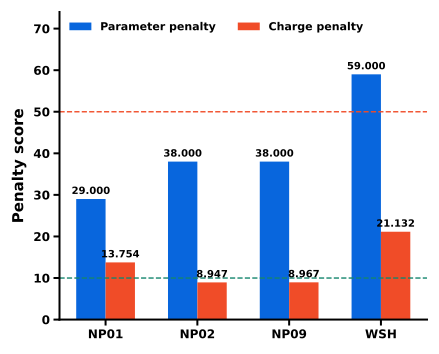

,ligand,parameter_penalty,charge_penalty,formal_charge
0,NP01,29.0,13.754,1
1,NP02,38.0,8.947,0
2,NP09,38.0,8.967,0
3,WSH,59.0,21.132,0


In [4]:
fig,ax=plt.subplots(figsize=mm(155,125)); x=np.arange(len(ids)); w=.32
for off,col,key,label in [(-w/2,B,'parameter_penalty','Parameter penalty'),(w/2,D,'charge_penalty','Charge penalty')]:
    bars=ax.bar(x+off,s[key],w,color=col,label=label)
    ax.bar_label(bars,labels=[f'{v:.3f}' for v in s[key]],padding=3,fontsize=10,fontweight='bold')
for v,col in [(10,T),(50,D)]: ax.axhline(v,color=col,ls='--',lw=1.4)
ax.set(xticks=x,xticklabels=ids,ylabel='Penalty score',ylim=(0,74)); ax.legend(loc='upper left',ncol=2,prop={'size':11,'weight':'bold'}); finish(fig,'01_maximum_penalties')
save_table(s[['ligand','parameter_penalty','charge_penalty','formal_charge']],'05_penalty_summary')


## 4. Atom-level charge penalties
All explicitly reported atom charge penalties are retained. The plot shows the number of atoms per penalty band, and the table identifies every atom with penalty ≥10.

,ligand,atom,atom_type,charge,charge_penalty,band
22,NP01,C23,CG2DC1,0.005,13.754,10–50
23,NP01,C24,CG2DC2,-0.517,12.342,10–50
30,NP01,C31,CG2DC2,0.111,11.917,10–50
207,WSH,C23,CG311,0.099,21.132,10–50
203,WSH,C19,CG2R53,0.546,19.455,10–50
205,WSH,C21,CG2DC1,-0.092,18.538,10–50
200,WSH,C16,CG2R61,0.187,18.458,10–50
212,WSH,N28,NG2D1,-0.504,17.697,10–50
213,WSH,N29,NG2R51,0.363,17.371,10–50
202,WSH,C18,CG2R61,-0.053,16.290,10–50


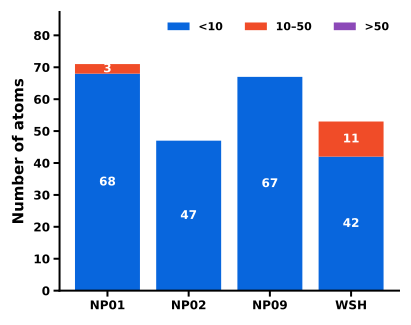

In [5]:
atoms['band']=pd.cut(atoms.charge_penalty,[-np.inf,10,50,np.inf],labels=['<10','10–50','>50'],right=True)
# Classify exactly 10 in the review band (rather than the low band).
atoms.loc[atoms.charge_penalty==10,'band']='10–50'
counts=pd.crosstab(atoms.ligand,atoms.band).reindex(index=ids,columns=['<10','10–50','>50'],fill_value=0)
save_table(atoms,'06_atom_charges',False)
save_table(atoms[atoms.charge_penalty>=10].sort_values(['ligand','charge_penalty'],ascending=[True,False]),'07_flagged_atom_charges')
fig,ax=plt.subplots(figsize=mm(145,115)); bottom=np.zeros(4)
for label,col in zip(counts.columns,[B,D,P]):
    vals=counts[label].to_numpy(); bars=ax.bar(ids,vals,bottom=bottom,color=col,label=label)
    for b,v in zip(bars,vals):
        if v: ax.text(b.get_x()+b.get_width()/2,b.get_y()+v/2,str(v),ha='center',va='center',color='white',fontweight='bold',fontsize=12)
    bottom+=vals
ax.set(ylabel='Number of atoms',ylim=(0,max(bottom)*1.23)); ax.legend(loc='upper right',ncol=3,prop={'size':11,'weight':'bold'}); finish(fig,'02_charge_penalty_bands')


## 5. Bonded parameter audit
A reported parameter type is counted once per ligand and section; repeated dihedral Fourier terms are grouped, retaining their maximum explicitly reported penalty. Entries without a penalty annotation are *not* assumed to have zero penalty. Counts therefore describe the reported stream, not every parameter in the full force field.

,ligand,kind,types,penalty,terms
133,NP01,Dihedral,CG2DC2 CG2DC1 CG2DC2 CG321,29.0,3
115,NP01,Dihedral,CG321 CG2D1O NG311 CG321,21.1,2
224,NP01,Improper,CG2D1O CG2DC1 CG321 NG311,18.5,1
123,NP01,Dihedral,OG301 CG2D2O CG2O5 CG2DC2,15.0,1
304,NP02,Dihedral,CG2R63 CG2R62 CG2R67 OG3R60,38.0,1
306,NP02,Dihedral,HGR62 CG2R62 CG2R67 OG3R60,36.0,1
311,NP02,Dihedral,CG2R62 CG2R67 OG3R60 CG2R62,31.0,1
261,NP02,Angle,CG2R62 CG2R67 OG3R60,30.5,1
284,NP02,Dihedral,OG301 CG2R61 CG2R62 OG3R60,11.5,1
419,NP09,Dihedral,CG2R63 CG2R62 CG2R67 OG3R60,38.0,1


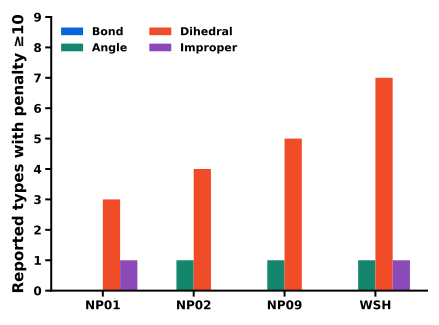

kind,ligand,Bond,Angle,Dihedral,Improper
0,NP01,6.0,3.5,29.0,18.5
1,NP02,NaN,30.5,38.0,NaN
2,NP09,NaN,30.5,38.0,NaN
3,WSH,4.0,16.0,59.0,41.0


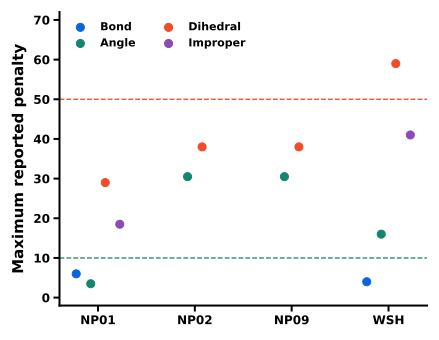

In [6]:
unique=terms.groupby(['ligand','kind','types'],sort=False,as_index=False).agg(penalty=('penalty','max'),terms=('coefficients','size'))
flagged=unique[unique.penalty>=10].sort_values(['ligand','penalty'],ascending=[True,False]).copy()
save_table(terms,'08_parameter_terms',False);save_table(unique,'09_unique_parameter_types',False);save_table(flagged,'10_flagged_parameter_types')
kinds=['Bond','Angle','Dihedral','Improper']
ct=pd.crosstab(flagged.ligand,flagged.kind).reindex(index=ids,columns=kinds,fill_value=0)
fig,ax=plt.subplots(figsize=mm(155,115)); x=np.arange(4); w=.19
for j,(kind,col) in enumerate(zip(kinds,[B,T,D,P])):
    vals=ct[kind]; ax.bar(x+(j-1.5)*w,vals,w,color=col,label=kind)
ax.set(xticks=x,xticklabels=ids,ylabel='Reported types with penalty ≥10',ylim=(0,max(ct.max())+2));ax.yaxis.set_major_locator(MaxNLocator(integer=True));ax.legend(loc='upper left',ncol=2,prop={'size':11,'weight':'bold'});finish(fig,'03_flagged_parameter_counts')
maxima=unique.pivot_table(index='ligand',columns='kind',values='penalty',aggfunc='max').reindex(index=ids,columns=kinds)
save_table(maxima.reset_index(),'11_maximum_penalty_by_type')
fig,ax=plt.subplots(figsize=mm(155,120)); x=np.arange(4)
for j,(kind,col) in enumerate(zip(kinds,[B,T,D,P])):
    vals=maxima[kind].to_numpy(); ax.scatter(x+(j-1.5)*.15,vals,s=65,color=col,label=kind,zorder=3)
for v,col in [(10,T),(50,D)]: ax.axhline(v,ls='--',color=col,lw=1.3)
ax.set(xticks=x,xticklabels=ids,ylabel='Maximum reported penalty',ylim=(-2,72));ax.legend(loc='upper left',ncol=2,prop={'size':11,'weight':'bold'});finish(fig,'04_penalty_by_parameter_type')


## 6. Locate high-penalty proper torsions
Enumerate connected four-atom paths in the original topology; match exact CGenFF atom-type sequences in either direction. Improper parameters are not mapped by this method. Multiple paths can share one parameter type. The ring membership flag comes from the stream RING records.

,ligand,atom_sequence,types,penalty,central_bond_in_reported_ring
0,NP01,C24–C23–C31–C32,CG2DC2 CG2DC1 CG2DC2 CG321,29.0,True
3,NP02,C9–C8–C7–O23,CG2R63 CG2R62 CG2R67 OG3R60,38.0,True
7,NP09,C23–C22–C21–O34,CG2R63 CG2R62 CG2R67 OG3R60,38.0,True
8,NP09,C9–C8–C7–O41,CG2R63 CG2R62 CG2R67 OG3R60,38.0,True
15,WSH,N30–C23–N28–C21,NG2S1 CG311 NG2D1 CG2DC1,59.0,True


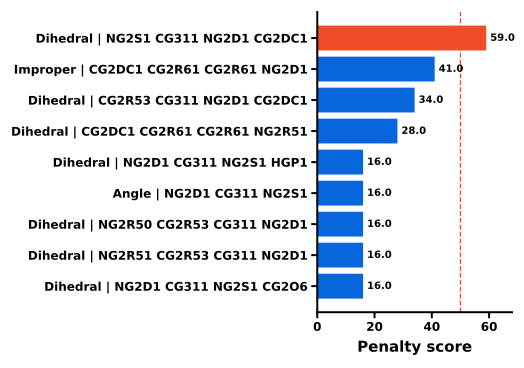

In [7]:
torsions=[]
for l,(amap,bonds) in graphs.items():
    adj=defaultdict(set)
    for a,b in bonds: adj[a].add(b);adj[b].add(a)
    rings=[line.split()[3:] for line in raw[l][l+'.str'].splitlines() if line.startswith('!RING ')]
    for row in flagged[(flagged.ligand==l)&(flagged.kind=='Dihedral')].itertuples():
        target=tuple(row.types.split()); paths=set()
        for b,c in bonds:
            for a,d in itertools.product(adj[b]-{c},adj[c]-{b}):
                if a==d: continue
                path=(a,b,c,d); ts=tuple(amap[i]['atom_type'] for i in path)
                if ts==target: paths.add(path)
                elif ts[::-1]==target: paths.add(path[::-1])
        for path in sorted(paths):
            ring=any(any({path[1],path[2]}=={r[i],r[(i+1)%len(r)]} for i in range(len(r))) for r in rings if r)
            torsions.append(dict(ligand=l,atom_sequence='–'.join(path),types=row.types,penalty=row.penalty,central_bond_in_reported_ring=ring))
tor=pd.DataFrame(torsions);save_table(tor,'12_flagged_torsion_paths',False)
display(tor[tor.penalty==tor.groupby('ligand').penalty.transform('max')])
w=flagged[flagged.ligand=='WSH'].sort_values('penalty')
fig,ax=plt.subplots(figsize=mm(185,130)); y=np.arange(len(w)); labels=[f'{k} | {t}' for k,t in zip(w.kind,w.types)]
bars=ax.barh(y,w.penalty,color=[D if p>50 else B for p in w.penalty]);ax.bar_label(bars,fmt='%.1f',padding=4,fontsize=10,fontweight='bold');ax.axvline(50,color=D,ls='--',lw=1.3);ax.set(yticks=y,yticklabels=labels,xlabel='Penalty score',xlim=(0,68));finish(fig,'05_WSH_flagged_parameters')


## 7. Warnings and validation priorities
The warnings are verbatim diagnostic lines, not evidence of a failed ligand. The full error log remains embedded. No explicit fatal/error keyword does not prove that the output is scientifically valid.

In [8]:
save_table(pd.DataFrame(warning_rows),'13_warnings')
rows=[]
for l in ids:
    a=atoms[atoms.ligand==l];u=unique[unique.ligand==l];r=s[s.ligand==l].iloc[0]
    rows.append(dict(ligand=l,charge_penalty_ge10=int((a.charge_penalty>=10).sum()),reported_parameter_types_ge10=int((u.penalty>=10).sum()),reported_parameter_types_gt50=int((u.penalty>50).sum()),priority='Extensive validation / optimisation' if max(r.parameter_penalty,r.charge_penalty)>50 else 'Basic validation'))
save_table(pd.DataFrame(rows),'14_validation_priorities')
print('All four archives parsed successfully. No MD production approval is inferred.')


,ligand,warning
0,NP01,readprm warning: IMPROPER parameter not in canonical format
1,NP01,readpar warning: DIHEDRAL parameters not sorted
2,NP01,readpar warning: IMPROPER parameters not sorted
3,NP02,readprm warning: IMPROPER parameter not in canonical format
4,NP02,readpar warning: DIHEDRAL parameters not sorted
5,NP02,readpar warning: IMPROPER parameters not sorted
6,NP09,readprm warning: IMPROPER parameter not in canonical format
7,NP09,readpar warning: DIHEDRAL parameters not sorted
8,NP09,readpar warning: IMPROPER parameters not sorted
9,WSH,readprm warning: IMPROPER parameter not in canonical format


,ligand,charge_penalty_ge10,reported_parameter_types_ge10,reported_parameter_types_gt50,priority
0,NP01,3,4,0,Basic validation
1,NP02,0,5,0,Basic validation
2,NP09,0,6,0,Basic validation
3,WSH,11,9,1,Extensive validation / optimisation


All four archives parsed successfully. No MD production approval is inferred.


## Interpretation and next steps
- NP01 has charge and bonded-parameter analogies requiring basic validation. NP02 and NP09 have low maximum charge penalties but bonded terms requiring review.
- WSH has a reported dihedral penalty of 59. Inspect the matched ring-associated torsion and assess coupled ring conformations using appropriate quantum-mechanical reference calculations before production use. A torsion-only energy term is not a full QM/MM energy profile.
- Successful topology generation, net-charge agreement and coordinate preservation do not establish force-field accuracy. Validate compatible CHARMM36m/CGenFF 5.0 topology conversion, missing parameters, geometries, relevant conformational energetics and system setup before MD. Do not treat this audit as evidence of affinity or selectivity.
- Reported counts apply to the supplied stream files and their explicit penalty annotations. The returned MOL2 stereochemistry and bond-order equivalence were not independently established by this notebook.